# Natural language to data visualisation (NL2VIS)

UTS Advanced NLP, Assessment 3. The notebook turns a plain-English question about a table into a chart, trained and tested on [nvBench](https://github.com/TsinghuaDatabaseGroup/nvBench) (Luo et al., SIGMOD 2021).

**Research question:** does schema-aware fine-tuning of a seq2seq transformer produce more correct chart specifications than a rule-based baseline and few-shot prompting?

Every system writes the same JSON chart specification, which one executor runs on the table:

```json
{"chart_type": "bar", "x": "day", "y": "tip", "aggregation": "avg", "group_by": "day", "bin": null, "filters": [], "sort": null}
```

| # | System | Model | Input |
|---|---|---|---|
| 1 | `rule_based` | keyword rules + fuzzy column matching | question + table |
| 2 | `few_shot_t5` | Flan-T5-base, prompted | question + schema + 4 examples |
| 3 | `few_shot_llm` | Qwen2.5-1.5B-Instruct, prompted | question + schema + 4 examples |
| 4 | `ft_no_schema` | Flan-T5-base, fine-tuned (ablation) | question only |
| 5 | `ft_schema` | Flan-T5-base, fine-tuned | question + **serialised schema** |

**Part A (sections 1-18)** only defines functions. **Part B (sections 19-30)** runs the pipeline: data, models, evaluation, figures and a demo. Trained models and predictions are cached, so a rerun skips finished work.

# Part A: definitions

## 1. Install

Run once, then restart the kernel. On Colab, PyTorch is already installed.

In [1]:
# %pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cu128
# %pip install pandas==2.3.1 numpy==2.2.6 matplotlib==3.10.3 rapidfuzz==3.13.0 transformers==4.53.2 accelerate==1.8.1 "sentencepiece>=0.2.1" plotly==6.2.0 scipy==1.18.1

## 2. Setup and configuration

All imports and every setting of the project. Paths are relative to this notebook.

In [2]:
from __future__ import annotations

import gc
import json
import math
import operator
import random
import re
import shutil
import sqlite3
import tempfile
import time
import urllib.request
import zipfile
from collections import Counter
from contextlib import closing
from dataclasses import dataclass, field, replace
from functools import lru_cache
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.patches import FancyBboxPatch
from pandas.api.types import is_bool_dtype, is_numeric_dtype
from rapidfuzz import fuzz
from scipy.stats import binomtest

ROOT = Path.cwd()
CONFIG: dict[str, Any] = {
    "seed": 42,
    "paths": {
        "raw_dir": "data/raw",                  # NVBench.json and database/<db_id>/<db_id>.sqlite
        "processed_dir": "data/processed",      # splits and table schemas
        "handwritten_dir": "data/handwritten",  # real CSVs of the hand-written test set
        "output_dir": "outputs",                # fine-tuned models
        "results_dir": "results",               # tables, predictions, scores
        "figures_dir": "figures",               # PNG figures for the report
    },
    "nvbench_url": "https://raw.githubusercontent.com/TsinghuaDatabaseGroup/nvBench/544fbc218a2c2fd5dac7591371e3e01ccd6afb93/",
    "chart_types": ["bar", "line", "scatter"],  # pie is converted too, but out of scope
    "split_fractions": {"test": 0.1, "val": 0.1},
    "split_candidates": 2000,  # random database splits tried; the best-balanced one is kept
    "schema": {"sample_values": 3, "max_value_chars": 20},
    "models": {"t5": "google/flan-t5-base", "llm": "Qwen/Qwen2.5-1.5B-Instruct"},
    "systems": {
        "rule_based": {"kind": "rules"},
        "few_shot_t5": {"kind": "t5_few_shot"},
        "few_shot_llm": {"kind": "llm_few_shot"},
        "ft_no_schema": {"kind": "t5_finetuned", "use_schema": False},
        "ft_schema": {"kind": "t5_finetuned", "use_schema": True},
    },
    "training": {"epochs": 8, "batch_size": 16, "learning_rate": 3e-4, "warmup_ratio": 0.05,
                 "weight_decay": 0.01, "max_input_tokens": 512, "max_target_tokens": 128},
    "generation": {"batch_size": 32, "num_beams": 1, "max_new_tokens": 128, "few_shot_max_input_tokens": 1024,
                   "llm_batch_size": 8, "llm_max_new_tokens": 160},
}
PATHS = {name: ROOT / path for name, path in CONFIG["paths"].items()}


def set_seed(seed: int) -> None:
    """Seed Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


set_seed(CONFIG["seed"])

## 3. Loading nvBench

Each nvBench entry is one visualisation: SQL plus an optional `BIN x BY YEAR/MONTH/WEEKDAY` clause, a chart label, the Spider database it runs on, 1-9 questions, and `vis_obj` (chart data computed by nvBench). Each database is a SQLite file at `database/<db_id>/<db_id>.sqlite`, and each table is loaded as a DataFrame.

In [3]:
@dataclass(frozen=True)
class VisRecord:
    """One nvBench visualisation and the questions that ask for it."""

    key: str
    db_id: str
    chart: str  # Bar, Line, Scatter, Pie, Stacked Bar, Grouping Line or Grouping Scatter
    hardness: str
    sql: str
    binning: str  # e.g. "BIN date BY YEAR", or ""
    questions: tuple[str, ...]
    vis_obj: dict = field(compare=False, repr=False)


def load_nvbench(path: Path) -> list[VisRecord]:
    raw = json.loads(path.read_text(encoding="utf-8"))
    return [
        VisRecord(key, e["db_id"], e["chart"], e["hardness"], " ".join(e["vis_query"]["data_part"]["sql_part"].split()),
                  e["vis_query"]["data_part"]["binning"].strip(), tuple(q.strip() for q in e["nl_queries"] if q.strip()), e["vis_obj"])
        for key, e in raw.items()
    ]


def database_file(db_id: str) -> Path:
    return PATHS["raw_dir"] / "database" / db_id / f"{db_id}.sqlite"


def open_database(db_file: Path) -> sqlite3.Connection:
    """Open read-only; invalid UTF-8 in a few databases is replaced."""
    connection = sqlite3.connect(db_file.resolve().as_uri() + "?mode=ro", uri=True)
    connection.text_factory = lambda raw: raw.decode("utf-8", errors="replace")
    return connection


@lru_cache(maxsize=None)
def table_columns(db_file: Path) -> dict[str, list[str]]:
    with closing(open_database(db_file)) as connection:
        names = [row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type = 'table'")]
        return {name: [c[1] for c in connection.execute(f'PRAGMA table_info("{name}")')] for name in names}


@lru_cache(maxsize=64)
def load_table(db_file: Path, table: str) -> pd.DataFrame:
    """Load one table (cached: do not modify the result)."""
    with closing(open_database(db_file)) as connection:
        return pd.read_sql_query(f'SELECT * FROM "{table}"', connection)


def execute_sql(db_file: Path, sql: str) -> list[tuple]:
    with closing(open_database(db_file)) as connection:
        return connection.execute(sql).fetchall()

## 4. Chart specification

Rows are filtered (all filters must hold), grouped by `group_by` (always the x column) with `y` aggregated, then sorted.

| Field | Values |
|---|---|
| `chart_type` | bar, line, scatter (pie reserved) |
| `x`, `y` | column names; `y = "*"` counts rows |
| `aggregation` | null, count, sum, avg, min, max |
| `group_by` | null, or x when there is an aggregation |
| `bin` | null, year, month, weekday (groups a date x) |
| `filters` | list of `{column, op, value}`, op in `= != > < >= <=` |
| `sort` | null or `{by: x or y, order: asc or desc}` |

In [4]:
CHART_TYPES = ("bar", "line", "scatter", "pie")
AGGREGATIONS = ("count", "sum", "avg", "min", "max")
FILTER_OPS = ("=", "!=", ">", "<", ">=", "<=")
BINS = ("year", "month", "weekday")
COUNT_ALL = "*"


class SpecError(ValueError):
    """A malformed chart spec."""


@dataclass(frozen=True)
class Filter:
    column: str
    op: str
    value: str | int | float


@dataclass(frozen=True)
class Sort:
    by: str     # "x" or "y"
    order: str  # "asc" or "desc"


@dataclass(frozen=True)
class ChartSpec:
    chart_type: str
    x: str
    y: str
    aggregation: str | None = None
    group_by: str | None = None
    bin: str | None = None
    filters: tuple[Filter, ...] = ()
    sort: Sort | None = None

    def to_dict(self) -> dict[str, Any]:
        return {"chart_type": self.chart_type, "x": self.x, "y": self.y, "aggregation": self.aggregation,
                "group_by": self.group_by, "bin": self.bin,
                "filters": [{"column": f.column, "op": f.op, "value": f.value} for f in self.filters],
                "sort": None if self.sort is None else {"by": self.sort.by, "order": self.sort.order}}

    def to_json(self) -> str:
        return json.dumps(self.to_dict(), ensure_ascii=False)

    @classmethod
    def from_dict(cls, d: Any) -> ChartSpec:
        """Build a spec from parsed JSON, raising SpecError if it is malformed."""
        if not isinstance(d, dict) or not {"chart_type", "x", "y"} <= d.keys():
            raise SpecError("a spec is an object with chart_type, x and y")
        group_by = d.get("group_by")
        spec = cls(_pick(d["chart_type"], CHART_TYPES, "chart_type"), _text(d["x"]), _text(d["y"]),
                   _optional(d.get("aggregation"), AGGREGATIONS, "aggregation"),
                   None if group_by in (None, "") else _text(group_by), _optional(d.get("bin"), BINS, "bin"),
                   tuple(_filter(f) for f in _list(d.get("filters"))), _sort(d.get("sort")))
        if spec.y == COUNT_ALL and spec.aggregation != "count":
            raise SpecError("y = '*' needs aggregation 'count'")
        if spec.bin and not spec.aggregation:
            raise SpecError("bin needs an aggregation")
        return spec


def parse_spec(text: str) -> ChartSpec:
    try:
        return ChartSpec.from_dict(json.loads(text))
    except json.JSONDecodeError as error:
        raise SpecError(f"invalid JSON: {error}") from error


def _pick(value: Any, options: tuple, name: str) -> str:
    if not isinstance(value, str) or value.strip().lower() not in options:
        raise SpecError(f"{name} must be one of {', '.join(options)}, got {value!r}")
    return value.strip().lower()


def _optional(value: Any, options: tuple, name: str) -> str | None:
    return None if value in (None, "", "none") else _pick(value, options, name)


def _text(value: Any) -> str:
    if not isinstance(value, str) or not value.strip():
        raise SpecError(f"expected a column name, got {value!r}")
    return value.strip()


def _list(value: Any) -> list:
    if value is not None and not isinstance(value, list):
        raise SpecError("filters must be a list")
    return value or []


def _filter(item: Any) -> Filter:
    if not isinstance(item, dict) or not {"column", "op", "value"} <= item.keys():
        raise SpecError("each filter needs column, op and value")
    op = {"==": "=", "<>": "!="}.get(item["op"], item["op"])
    if op not in FILTER_OPS or isinstance(item["value"], bool) or not isinstance(item["value"], (str, int, float)):
        raise SpecError(f"bad filter {item!r}")
    return Filter(_text(item["column"]), op, item["value"])


def _sort(item: Any) -> Sort | None:
    if item is None:
        return None
    if not isinstance(item, dict) or "by" not in item:
        raise SpecError("sort must be null or {by, order}")
    return Sort(_pick(item["by"], ("x", "y"), "sort.by"), _pick(item.get("order", "asc"), ("asc", "desc"), "sort.order"))


def match_name(name: str, options: list[str]) -> str | None:
    """Find a name exactly, else case-insensitively (SQL names ignore case)."""
    if name in options:
        return name
    folded = [o for o in options if o.lower() == name.lower()]
    return folded[0] if len(folded) == 1 else None

## 5. Converter: nvBench query to chart spec

A tokenizer and a small recursive-descent parser read nvBench's SQL. A query is converted, or rejected with a reason that belongs to a filtering stage:

1. **chart_type**: stacked and grouping charts (they need a series column);
2. **single_table**: joins, nested queries, set operations;
3. **operations**: anything else the spec cannot express (`LIKE`, `OR`, `LIMIT`, binning by day, ...);
4. **validation**: the spec does not reproduce nvBench's result (section 23);
5. **scope**: pie charts.

`COUNT(x)` grouped by x becomes `COUNT(*)`, `BETWEEN` becomes two filters, and a binned query becomes `group_by = x` plus `bin`. nvBench sometimes sorts by a bare column (`SUM(salary) ... ORDER BY salary`); its ids say this means "sort by y", so that is what the spec says.

In [5]:
NVBENCH_CHARTS = {"Bar": "bar", "Line": "line", "Scatter": "scatter", "Pie": "pie"}
GROUPED_CHARTS = ("Stacked Bar", "Grouping Line", "Grouping Scatter")
STAGES = ("chart_type", "single_table", "operations", "validation", "scope")
COMPARISONS = {"=": "=", "!=": "!=", "<>": "!=", ">": ">", "<": "<", ">=": ">=", "<=": "<="}
KEYWORDS = frozenset("SELECT FROM WHERE GROUP BY ORDER ASC DESC AND OR NOT LIKE IN BETWEEN IS NULL JOIN ON AS "
                     "LIMIT HAVING UNION INTERSECT EXCEPT DISTINCT".split())
TOKEN = re.compile(r"""\s*(?:(?P<string>'(?:[^']|'')*'|"(?:[^"]|"")*")|(?P<number>\d+(?:\.\d+)?(?!\w))"""
                   r"""|(?P<op>>=|<=|!=|<>|[=<>(),*])|(?P<word>[A-Za-z_][\w.]*)|(?P<other>\S))""")


class Unsupported(Exception):
    """A query the spec cannot express, with the filtering stage that drops it."""

    def __init__(self, stage: str, reason: str) -> None:
        super().__init__(reason)
        self.stage, self.reason = stage, reason


@dataclass(frozen=True)
class Conversion:
    table: str
    spec: ChartSpec
    sql_sort: str | None  # "x" or "y" if the SQL fixes the row order, else None


def tokenize(sql: str) -> list[tuple[str, str]]:
    return [(kind, text) for m in TOKEN.finditer(sql) for kind, text in m.groupdict().items() if text is not None]


class _Parser:
    """Reads the restricted SQL the spec can express; items are (aggregate or None, column)."""

    def __init__(self, tokens: list[tuple[str, str]]) -> None:
        self.tokens, self.i = tokens, 0

    def peek(self, ahead: int = 0) -> tuple[str, str]:
        return self.tokens[self.i + ahead] if self.i + ahead < len(self.tokens) else ("end", "")

    def next(self) -> tuple[str, str]:
        self.i += 1
        return self.peek(-1)

    def at(self, word: str) -> bool:
        kind, text = self.peek()
        return kind == "word" and text.upper() == word

    def take(self, word: str) -> bool:
        found = self.at(word)
        self.i += found
        return found

    def take_op(self, op: str) -> bool:
        found = self.peek() == ("op", op)
        self.i += found
        return found

    def expect(self, word: str) -> None:
        if not self.take(word):
            raise Unsupported("operations", f"expected {word}, got {self.peek()[1] or 'end'}")

    def column(self) -> str:
        kind, text = self.next()
        if kind != "word" or text.upper() in KEYWORDS:
            raise Unsupported("operations", f"unexpected {text.upper() or 'end'}")
        if self.peek() == ("op", "("):
            raise Unsupported("operations", f"function {text.upper()} outside SELECT")
        return text.split(".")[-1]  # drop a table alias such as T1.

    def item(self) -> tuple[str | None, str]:
        if self.at("DISTINCT") or self.peek() == ("op", "*"):
            raise Unsupported("operations", "DISTINCT" if self.at("DISTINCT") else "SELECT *")
        kind, text = self.peek()
        if kind == "word" and self.peek(1) == ("op", "("):
            if text.lower() not in AGGREGATIONS:
                raise Unsupported("operations", f"function {text.upper()}")
            self.i += 2
            if self.at("DISTINCT"):
                raise Unsupported("operations", "DISTINCT")
            result = (text.lower(), COUNT_ALL if self.take_op("*") else self.column())
            if not self.take_op(")"):
                raise Unsupported("operations", "expression inside an aggregate")
        else:
            result = (None, self.column())
        if self.peek() in (("other", "-"), ("other", "+"), ("other", "/"), ("op", "*")):
            raise Unsupported("operations", "arithmetic expression")
        return result

    def literal(self) -> str | int | float:
        kind, text = self.next()
        if kind == "string":
            return text[1:-1].replace(text[0] * 2, text[0])
        sign = 1
        if (kind, text) == ("other", "-"):
            sign, (kind, text) = -1, self.next()
        if kind == "number":
            return sign * (float(text) if "." in text else int(text))
        raise Unsupported("operations", "WHERE compares two columns" if kind == "word" and text.upper() not in KEYWORDS
                          else f"WHERE value {text.upper() or 'end'}")

    def condition(self) -> list[Filter]:
        if self.peek() == ("op", "(") or self.at("NOT"):
            raise Unsupported("operations", "parentheses in WHERE" if self.peek() == ("op", "(") else "WHERE operator NOT")
        column = self.column()
        kind, text = self.next()
        if kind == "word" and text.upper() == "BETWEEN":
            low = self.literal()
            self.expect("AND")
            return [Filter(column, ">=", low), Filter(column, "<=", self.literal())]
        if kind == "op" and text in COMPARISONS:
            return [Filter(column, COMPARISONS[text], self.literal())]
        raise Unsupported("operations", f"WHERE operator {text.upper() or 'end'}")


def convert(chart: str, sql: str, binning: str, tables: dict[str, list[str]]) -> Conversion:
    """Convert one nvBench query into a chart spec, or raise Unsupported."""
    if chart not in NVBENCH_CHARTS:
        raise Unsupported("chart_type", f"{chart} (needs a series column)" if chart in GROUPED_CHARTS else f"unknown chart {chart}")
    tokens = tokenize(sql)
    words = [text.upper() for kind, text in tokens if kind == "word"]
    if words.count("SELECT") > 1:
        raise Unsupported("single_table", "nested query")
    if {"UNION", "INTERSECT", "EXCEPT"} & set(words):
        raise Unsupported("single_table", "set operation")
    if "JOIN" in words:
        raise Unsupported("single_table", "join")
    unit = bin_column = None
    if binning:
        m = re.fullmatch(r"BIN\s+(\S+)\s+BY\s+(\w+)", binning, flags=re.IGNORECASE)
        if m is None or m.group(2).lower() not in BINS:
            raise Unsupported("operations", f"binning by {binning.split()[-1].lower()}")
        bin_column, unit = m.group(1).split(".")[-1], m.group(2).lower()

    p = _Parser(tokens)
    p.expect("SELECT")
    items = [p.item()]
    while p.take_op(","):
        items.append(p.item())
    if len(items) != 2:
        raise Unsupported("operations", f"{len(items)} selected expressions")
    p.expect("FROM")
    table_name = p.column()
    if p.take_op(","):
        raise Unsupported("single_table", "join")
    if p.take("AS") or (p.peek()[0] == "word" and p.peek()[1].upper() not in KEYWORDS):
        p.next()  # table alias
    filters = []
    if p.take("WHERE"):
        filters += p.condition()
        while p.take("AND"):
            filters += p.condition()
        if p.at("OR"):
            raise Unsupported("operations", "OR in WHERE")
    group = []
    if p.take("GROUP"):
        p.expect("BY")
        group.append(p.column())
        while p.take_op(","):
            group.append(p.column())
    order = None
    if p.take("ORDER"):
        p.expect("BY")
        order = (p.item(), "desc" if p.take("DESC") else "asc")
        p.take("ASC")
        if p.take_op(","):
            raise Unsupported("operations", "ORDER BY several columns")
    if p.peek()[0] != "end":
        raise Unsupported("operations", f"{p.peek()[1].upper()} clause")

    table = match_name(table_name, list(tables))
    if table is None:
        raise Unsupported("operations", f"unknown table {table_name}")

    def resolve(name: str) -> str:
        found = name if name == COUNT_ALL else match_name(name, tables[table])
        if found is None:
            raise Unsupported("operations", f"unknown column {name}")
        return found

    (x_agg, x_col), (aggregation, y_col) = items
    if x_agg is not None:
        raise Unsupported("operations", "aggregate on the x axis")
    x, y = resolve(x_col), resolve(y_col)
    if y == COUNT_ALL and aggregation != "count":
        raise Unsupported("operations", "SELECT *")
    if len(group) > 1:
        raise Unsupported("operations", "GROUP BY several columns")
    group_by = resolve(group[0]) if group else None
    if unit:
        if resolve(bin_column) != x:
            raise Unsupported("operations", "binned column differs from x")
        if aggregation is None:
            raise Unsupported("operations", "binning without aggregation")
        group_by = group_by or x  # the bin does the grouping
    if group_by and aggregation is None:
        raise Unsupported("operations", "GROUP BY without aggregation")
    if aggregation and group_by is None:
        raise Unsupported("operations", "aggregation without GROUP BY")
    if group_by and group_by != x:
        raise Unsupported("operations", "GROUP BY column differs from x")
    if aggregation == "count" and y == x:
        y = COUNT_ALL

    sort = sql_sort = None
    if order:
        (o_agg, o_col), direction = order
        o_col = resolve(o_col)
        if o_agg == "count" and o_col == x:
            o_col = COUNT_ALL
        if o_agg is None and o_col == x:
            sort, sql_sort = Sort("x", direction), "x"
        elif (o_agg, o_col) == (aggregation, y):
            sort, sql_sort = Sort("y", direction), "y"
        elif o_agg is None and aggregation and o_col == y:
            sort = Sort("y", direction)  # nvBench quirk: a bare column stands for the y axis
        else:
            raise Unsupported("operations", "ORDER BY a column that is not on an axis")
    filters = tuple(Filter(resolve(f.column), f.op, f.value) for f in filters)
    spec = ChartSpec(NVBENCH_CHARTS[chart], x, y, aggregation, group_by, unit, filters, sort)
    return Conversion(table, spec, None if unit else sql_sort)

## 6. Executor: run a spec on a DataFrame

One function turns a spec and a table into chart data (columns `x`, `y`). It runs gold specs, model outputs and uploaded CSVs alike, and follows SQLite where the two could differ: a NULL fails every filter and forms its own group, `COUNT(col)` skips NULLs, `SUM`/`AVG` read numbers out of text, and sorting puts NULL, then numbers, then text. Binning reads x as a date (most formats) and maps it to a year, month or weekday; binned charts come in calendar order unless sorted.

In [6]:
MONTHS = ("Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec")
WEEKDAYS = ("Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun")
_COMPARE = {"=": operator.eq, "!=": operator.ne, ">": operator.gt, "<": operator.lt, ">=": operator.ge, "<=": operator.le}
_NUMBER = r"\s*[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"


class ExecutionError(ValueError):
    """A well-formed spec that cannot run on the table (e.g. an unknown column)."""


def is_null(v: Any) -> bool:
    return v is None or (isinstance(v, (float, np.floating)) and math.isnan(v))


def as_number(v: Any) -> float | None:
    """A cell or literal as a number, or None if it is not numeric."""
    if isinstance(v, (bool, np.bool_)) or is_null(v):
        return None
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    return float(v) if isinstance(v, str) and re.fullmatch(_NUMBER + r"\s*", v) else None


def sqlite_sort_key(v: Any) -> tuple[int, float, str]:
    """Order like SQLite: NULL, then numbers, then text."""
    if is_null(v):
        return (0, 0.0, "")
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        return (1, float(v), "")
    return (2, 0.0, str(v))


def _x_sort_key(v: Any, unit: str | None) -> tuple[int, float, str]:
    calendar = {"month": MONTHS, "weekday": WEEKDAYS}.get(unit or "", ())
    return (1, float(calendar.index(v)), "") if v in calendar else sqlite_sort_key(v)


def _sqlite_number(v: Any) -> float:
    """A non-NULL cell as SQLite's SUM and AVG read it (non-numeric text is 0)."""
    number = as_number(v)
    if number is not None:
        return number
    m = re.match(_NUMBER, str(v))
    return float(m.group()) if m else 0.0


def _compare(cell: Any, op: str, value: Any) -> bool:
    if is_null(cell):
        return False
    left, right = as_number(cell), as_number(value)
    if left is None or right is None:
        left, right = str(cell), str(value)
    return _COMPARE[op](left, right)


def _aggregate(values: pd.Series, how: str) -> Any:
    present = [v for v in values.tolist() if not is_null(v)]
    if how == "count":
        return len(present)
    if not present:
        return None
    if how in ("sum", "avg"):
        total = sum(_sqlite_number(v) for v in present)
        return total if how == "sum" else total / len(present)
    return (min if how == "min" else max)(present, key=sqlite_sort_key)


def bin_values(cells: pd.Series, unit: str) -> pd.Series:
    """Map date cells to a year (int), month name or weekday name; unreadable dates become None."""
    def as_text(v):
        n = as_number(v)
        return None if is_null(v) else str(int(n)) if n is not None and n.is_integer() else str(v).strip()

    dates = pd.to_datetime(cells.map(as_text), errors="coerce", format="mixed")
    label = {"year": lambda d: int(d.year), "month": lambda d: MONTHS[d.month - 1], "weekday": lambda d: WEEKDAYS[d.dayofweek]}[unit]
    return pd.Series([None if pd.isna(d) else label(d) for d in dates], index=cells.index, dtype=object)


def execute_spec(spec: ChartSpec, table: pd.DataFrame) -> pd.DataFrame:
    """Run a spec on a table; return its chart data with columns x and y."""
    columns = [str(c) for c in table.columns]

    def column(name: str) -> str:
        found = match_name(name, columns)
        if found is None:
            raise ExecutionError(f"unknown column {name!r}")
        return found

    x = column(spec.x)
    y = COUNT_ALL if spec.y == COUNT_ALL else column(spec.y)
    if y == COUNT_ALL and spec.aggregation != "count":
        raise ExecutionError("y = '*' needs aggregation 'count'")
    if spec.group_by is not None and (column(spec.group_by) != x or spec.aggregation is None):
        raise ExecutionError("group_by must be the x column and needs an aggregation")
    if spec.bin and not spec.aggregation:
        raise ExecutionError("bin needs an aggregation")
    frame = table
    for f in spec.filters:
        frame = frame[frame[column(f.column)].map(lambda cell: _compare(cell, f.op, f.value)).astype(bool)]
    if spec.aggregation is None:
        rows = list(zip(frame[x].tolist(), frame[y].tolist()))
    else:
        keys = frame[x]
        if spec.bin:
            keys = bin_values(keys, spec.bin)
            frame, keys = frame[keys.notna()], keys[keys.notna()]  # rows without a readable date are dropped
        values = pd.Series(1, index=frame.index) if y == COUNT_ALL else frame[y]
        rows = [(k, _aggregate(g, spec.aggregation)) for k, g in values.groupby(keys, dropna=False, sort=False)]
        if spec.bin:
            rows.sort(key=lambda r: _x_sort_key(r[0], spec.bin))
    if spec.sort:
        key = (lambda r: _x_sort_key(r[0], spec.bin)) if spec.sort.by == "x" else (lambda r: sqlite_sort_key(r[1]))
        rows.sort(key=key, reverse=spec.sort.order == "desc")
    return pd.DataFrame(rows, columns=["x", "y"], dtype=object)

## 7. Comparing chart data

Values are normalised (NaN becomes None, numbers rounded to 6 significant digits). Two charts match if they hold the same multiset of `(x, y)` rows and, when sorted, the same sequence of sort-axis values (ties may come in any order).

The gold chart data is **nvBench's SQL executed on SQLite**: nvBench's stored `vis_obj` disagrees with it in about 13% of cases (section 23). Binned charts are the exception, since SQLite cannot bin: they are checked against `vis_obj` after undoing its labels (`Thur`, `Sept`) and ignoring the empty bins it fills with 0.

In [7]:
def normalise_value(v: Any) -> Any:
    if isinstance(v, np.generic):
        v = v.item()
    if is_null(v):
        return None
    if isinstance(v, bool):
        return int(v)
    if isinstance(v, (int, float)):
        return float(f"{float(v):.6g}")
    return v.decode("utf-8", errors="replace") if isinstance(v, bytes) else v


def chart_rows(rows) -> list[tuple]:
    """Normalised (x, y) rows of executor output (a DataFrame) or of query results (a list)."""
    if isinstance(rows, pd.DataFrame):
        rows = list(rows.itertuples(index=False, name=None))
    return [(normalise_value(r[0]), normalise_value(r[1])) for r in rows]


def same_chart_data(predicted: list[tuple], gold: list[tuple], sort_by: str | None = None) -> bool:
    if Counter(map(repr, predicted)) != Counter(map(repr, gold)):
        return False
    axis = {"x": 0, "y": 1}.get(sort_by)
    return axis is None or [r[axis] for r in predicted] == [r[axis] for r in gold]


def _loose(v: Any, from_vis_obj: bool, binned: bool = False) -> Any:
    """Undo nvBench's display formatting of vis_obj values."""
    v = normalise_value(v)
    if not isinstance(v, str):
        return v
    t = v.strip()
    if re.fullmatch(r"[+-]?\d+(\.\d+)?", t):
        return float(f"{float(t):.6g}")
    if from_vis_obj and re.fullmatch(r"\d{4}-01-01", t):
        return float(t[:4])
    t = t[:10] if re.match(r"\d{4}-\d{2}-\d{2}", t) else t
    return t[:3].title() if binned and from_vis_obj else t  # binned labels: 'Thur' and 'Sept' become 'Thu' and 'Sep'


def matches_vis_obj(chart: pd.DataFrame, vis_obj: dict, binned: bool = False) -> bool:
    xs = vis_obj["x_data"][0] if vis_obj["x_data"] else []
    ys = vis_obj["y_data"][0] if vis_obj["y_data"] else []
    ours = [(_loose(x, False), _loose(y, False)) for x, y in chart.itertuples(index=False, name=None)]
    theirs = [(_loose(x, True, binned), _loose(y, True)) for x, y in zip(xs, ys)]
    if binned:  # nvBench lists empty weekdays or months with y = 0
        present = {x for x, _ in ours}
        theirs = [(x, y) for x, y in theirs if y != 0 or x in present]
    return same_chart_data(ours, theirs)

## 8. Schema serialiser

The schema-aware model input: one line per table (T5 has no newline token) with each column's name, type inferred from its values (number, date or text, so a CSV works too) and its first three distinct values, e.g.

`table: county | columns: County_Id (number: 1, 2, 3); County_name (text: Howard, Baltimore County, Colony); Population (number: 21000, 90000, 79000)`

In [8]:
def column_type(series: pd.Series) -> str:
    values = series.dropna()
    if values.empty or is_bool_dtype(series):
        return "text"
    if is_numeric_dtype(series):
        return "number"
    text = values.astype(str).str.strip()
    if text.str.fullmatch(r"[+-]?\d+(?:\.\d+)?").all():
        return "number"
    return "date" if text.str.match(r"\d{4}-\d{1,2}-\d{1,2}|\d{1,2}/\d{1,2}/\d{2,4}").mean() >= 0.9 else "text"


def format_value(v: Any, max_chars: int) -> str:
    if isinstance(v, float):
        return str(int(v)) if v.is_integer() else f"{v:.6g}"
    text = " ".join(str(v).split())
    return text if len(text) <= max_chars else text[: max_chars - 3] + "..."


def serialise_table(name: str, table: pd.DataFrame, sample_values: int = 3, max_value_chars: int = 20) -> str:
    columns = [
        f"{c} ({column_type(table[c])}: {', '.join(format_value(v, max_value_chars) for v in pd.unique(table[c].dropna())[:sample_values])})"
        for c in table.columns
    ]
    return f"table: {name} | columns: " + "; ".join(columns)

## 9. Splits and file helpers

Whole databases go to one split, so test schemas are never seen in training. A candidate split shuffles the databases and fills test, then validation, up to their share of questions. Of `split_candidates` seeded candidates, the one whose chart types, aggregations and bins are closest to the whole dataset is kept (a single shuffle once left line charts out of the test set).

In [9]:
SPLITS = ("train", "val", "test")


def example_strata(ex: dict) -> list[str]:
    return [f"chart={ex['chart_type']}", f"aggregation={ex['spec']['aggregation']}", f"bin={ex['spec']['bin']}"]


def _split_once(examples: list[dict], fractions: dict, rng: random.Random) -> dict[str, list[dict]]:
    counts = Counter(ex["db_id"] for ex in examples)
    databases = sorted(counts)
    rng.shuffle(databases)
    remaining, owner = iter(databases), {}
    for split in ("test", "val"):
        filled = 0
        while filled < fractions[split] * len(examples):
            db = next(remaining)
            owner[db], filled = split, filled + counts[db]
    owner |= {db: "train" for db in remaining}
    return {s: [ex for ex in examples if owner[ex["db_id"]] == s] for s in SPLITS}


def imbalance(splits: dict, examples: list[dict], strata=example_strata) -> float:
    """Largest relative gap between a category's share in val or test and its overall share."""
    overall = Counter(label for ex in examples for label in strata(ex))
    gaps = [0.0]
    for name in ("val", "test"):
        part = Counter(label for ex in splits[name] for label in strata(ex))
        gaps += [abs(part[l] / max(len(splits[name]), 1) - n / len(examples)) / (n / len(examples)) for l, n in overall.items()]
    return max(gaps)


def split_by_database(examples, fractions, seed, candidates=1, strata=example_strata) -> dict[str, list[dict]]:
    rng = random.Random(seed)
    options = [_split_once(examples, fractions, rng) for _ in range(candidates)]
    return options[0] if candidates == 1 else min(options, key=lambda s: imbalance(s, examples, strata))


def write_jsonl(path: Path, rows) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows), encoding="utf-8")


def read_jsonl(path: Path) -> list[dict]:
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def save_table(frame: pd.DataFrame, name: str) -> None:
    """Write a results table as CSV and as markdown."""
    PATHS["results_dir"].mkdir(parents=True, exist_ok=True)
    frame.to_csv(PATHS["results_dir"] / f"{name}.csv")
    header = [str(frame.index.name or "")] + [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join([str(i)] + [str(v) for v in row]) + " |" for i, row in frame.iterrows()]
    (PATHS["results_dir"] / f"{name}.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

## 10. Spec text: the T5 target

T5's vocabulary has no `{`, `}` or `<`, so the T5 systems write a lossless text form of the spec, turned into the JSON spec after generation (`group_by` is implied by x; operators are words):

`chart: bar ; x: Carrier ; y: Price ; agg: avg ; bin: none ; filters: Memory ge 32 and Carrier eq "Sprint" ; sort: y desc`

In [10]:
OP_WORDS = {"=": "eq", "!=": "ne", ">": "gt", "<": "lt", ">=": "ge", "<=": "le"}
WORD_OPS = {w: op for op, w in OP_WORDS.items()}
_FILTER_ITEM = re.compile(r'\s*(?P<column>[^"]+?)\s+(?P<op>eq|ne|gt|lt|ge|le)\s+(?P<value>"(?:[^"\\]|\\.)*"|-?\d+(?:\.\d+)?)(?:\s+and\s+|\s*$)')


def spec_to_text(spec: ChartSpec) -> str:
    filters = " and ".join(f"{f.column} {OP_WORDS[f.op]} {json.dumps(f.value, ensure_ascii=False)}" for f in spec.filters)
    sort = f"{spec.sort.by} {spec.sort.order}" if spec.sort else "none"
    return " ; ".join([f"chart: {spec.chart_type}", f"x: {spec.x}", f"y: {spec.y}", f"agg: {spec.aggregation or 'none'}",
                       f"bin: {spec.bin or 'none'}", f"filters: {filters or 'none'}", f"sort: {sort}"])


def text_to_spec(text: str) -> ChartSpec:
    fields = {}
    for part in text.split(";"):
        key, sep, value = part.partition(":")
        if not sep:
            raise SpecError(f"cannot read field {part.strip()!r}")
        fields[key.strip().lower()] = value.strip()
    if not {"chart", "x", "y"} <= fields.keys():
        raise SpecError("missing chart, x or y")
    none = lambda v: None if v is None or v.strip().lower() in ("", "none", "null") else v.strip()
    filters, i, raw = [], 0, fields.get("filters", "none")
    while none(raw) and i < len(raw):
        m = _FILTER_ITEM.match(raw, i)
        if m is None or m.end() == i:
            raise SpecError(f"cannot read filters {raw!r}")
        v = m.group("value")
        try:
            value = json.loads(v) if v.startswith('"') else float(v) if "." in v else int(v)
        except json.JSONDecodeError as error:
            raise SpecError(f"bad filter value {v!r}") from error
        filters.append({"column": m.group("column").strip(), "op": WORD_OPS[m.group("op")], "value": value})
        i = m.end()
    sort = none(fields.get("sort", "none"))
    agg = none(fields.get("agg"))
    return ChartSpec.from_dict({
        "chart_type": fields["chart"], "x": fields["x"], "y": fields["y"], "aggregation": agg,
        "group_by": fields["x"] if agg else None, "bin": none(fields.get("bin")), "filters": filters,
        "sort": None if sort is None else {"by": sort.split()[0], "order": (sort.split() + ["asc"])[1]},
    })

## 11. Rule-based baseline

Keyword rules plus fuzzy column matching, with no training. Column names are split into words (`max_temperature_f` becomes "max temperature f") and fuzzy-matched to 1-3 word question phrases (RapidFuzz ratio ≥ 85). x is the column after a grouping cue ("for each", "by", "per"), else the first text or date column mentioned. Cue words set the chart type, aggregation, bin and sort; number comparisons ("more than 85") and quoted or verbatim cell values become filters.

In [11]:
CHART_CUES = [
    ("scatter", r"\bscatter|correlat|relationship|relation between|relates? to|\bagainst\b|\bvs\.? .*\bfor each\b"),
    ("line", r"\bline\b|\btrend|over time|over the years|through the years|changed? over|how .* (?:changed|moved|developed)"),
    ("pie", r"\bpie\b|proportion|percentage"),
    ("bar", r"\bbar\b|histogram|column chart"),
]
AGGREGATION_CUES = [
    ("avg", r"\b(average|mean|avg)\b"),
    ("count", r"\b(how many|number of|total number|count|counts|frequency)\b"),
    ("sum", r"\b(total|sum|combined|altogether)\b"),
    ("max", r"\b(maximum|max|highest|largest|biggest|most)\b"),
    ("min", r"\b(minimum|min|lowest|smallest|least|cheapest)\b"),
]
BIN_CUES = [("weekday", r"\b(weekdays?|day of (the )?week|days of (the )?week)\b"),
            ("month", r"\b(months?|monthly)\b"), ("year", r"\b(years?|yearly|annual(ly)?)\b")]
COMPARISON_CUES = [(">=", r"at least|no less than|>="), ("<=", r"at most|no more than|<="),
                   (">", r"more than|greater than|larger than|bigger than|higher than|above|over|exceeding|>"),
                   ("<", r"less than|fewer than|smaller than|lower than|below|under|<"),
                   ("!=", r"not equal to|other than|!="), ("=", r"equal to|equals|=")]
SORT_DESC = r"\b(desc|descending|high to low|highest to lowest|largest to smallest|biggest to smallest|decreasing|from high|z to a|latest first)\b"
SORT_ASC = r"\b(asc|ascending|low to high|lowest to highest|smallest to largest|increasing|from low|a to z|alphabetical(?:ly)?|earliest first)\b"
SORT_BY_X = r"\b(x[- ]?axis|the x|by x|alphabetical(?:ly)?|a to z|z to a|latest first|earliest first)\b"
GROUP_CUES = r"\b(for each|for every|of each|in each|for the different|per|by|across|grouped by|each)\b"


def column_words(name: str) -> str:
    return " ".join(re.sub(r"([a-z])([A-Z])", r"\1 \2", str(name)).replace("_", " ").lower().split())


def _singular(w: str) -> str:
    return w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w


def find_mentions(question: str, columns: list[str]) -> list[tuple[int, str]]:
    """(position, column) for every column the question refers to, in question order."""
    tokens = [(m.group().lower(), m.start()) for m in re.finditer(r"[A-Za-z0-9]+", question)]
    words = [_singular(t) for t, _ in tokens]
    mentions = []  # (position, score, column)
    for column in columns:
        verbatim = re.search(rf"(?<![A-Za-z0-9_]){re.escape(str(column).lower())}(?![A-Za-z0-9_])", question.lower())
        if verbatim:
            mentions.append((verbatim.start(), 100.0, column))
            continue
        target = " ".join(_singular(w) for w in column_words(column).split())
        if len(target) < 3:
            continue
        n, best = len(target.split()), (0.0, 0)
        for width in {max(1, n - 1), n, n + 1}:
            for i in range(len(words) - width + 1):
                score = fuzz.ratio(" ".join(words[i:i + width]), target)
                if score > best[0]:  # the first best phrase wins
                    best = (score, tokens[i][1])
        if best[0] >= 85:
            mentions.append((best[1], best[0], column))
    return [(pos, column) for pos, _, column in sorted(mentions, key=lambda m: (m[0], -m[1]))]


class RuleBased:
    """Keyword and fuzzy-matching baseline."""

    def __init__(self, chart_types: list[str]) -> None:
        self.chart_types = chart_types

    def predict(self, question: str, table: pd.DataFrame) -> ChartSpec:
        columns = [str(c) for c in table.columns]
        types = {c: column_type(table[c]) for c in columns}
        text = question.lower()
        mentions = find_mentions(question, columns)
        chart = next((n for n, cue in CHART_CUES if n in self.chart_types and re.search(cue, text)), "bar")
        aggregation = next((n for n, cue in AGGREGATION_CUES if re.search(cue, re.sub(f"{SORT_DESC}|{SORT_ASC}", " ", text))), None)
        cue_ends = [m.end() for m in re.finditer(GROUP_CUES, text)]
        candidates = ([c for p, c in mentions if any(0 <= p - e <= 25 for e in cue_ends)]
                      or [c for _, c in mentions if types[c] != "number"] or [c for _, c in mentions])
        x = candidates[0] if candidates else next((c for c in columns if types[c] != "number"), columns[0])
        if aggregation == "count":
            y = COUNT_ALL
        else:
            numeric = [c for _, c in mentions if types[c] == "number" and c != x]
            others = [c for _, c in mentions if c != x]
            fallback = [c for c in columns if types[c] == "number" and c != x] or [c for c in columns if c != x] or [x]
            y = (numeric or ([] if aggregation else others) or fallback)[0]
            if aggregation and types.get(y) != "number":
                aggregation, y = "count", COUNT_ALL
        unit = next((n for n, cue in BIN_CUES if re.search(cue, text)), None) if types[x] == "date" else None
        if unit and aggregation is None:
            aggregation, y = "count", COUNT_ALL
        order = "desc" if re.search(SORT_DESC, text) else "asc" if re.search(SORT_ASC, text) else None
        sort = Sort("x" if re.search(SORT_BY_X, text) else "y", order) if order else None
        filters = self._filters(question, table, types, mentions, x)
        return ChartSpec(chart, x, y, aggregation, x if aggregation else None, unit, tuple(filters), sort)

    @staticmethod
    def _filters(question, table, types, mentions, x) -> list[Filter]:
        filters, taken = [], []
        numeric = [(p, c) for p, c in mentions if types[c] == "number" and c != x]
        for op, cue in COMPARISON_CUES:
            for m in re.finditer(rf"(?:^|\W)(?:{cue})\s*(-?\d+(?:\.\d+)?)", question, flags=re.IGNORECASE):
                before = [c for p, c in numeric if p < m.start()]
                if before and not any(s < m.end() and m.start() < e for s, e in taken):
                    taken.append(m.span())
                    filters.append(Filter(before[-1], op, float(m.group(1)) if "." in m.group(1) else int(m.group(1))))
        lowered = question.lower()
        quoted = {q.lower() for pair in re.findall(r'"([^"]+)"|\'([^\']+)\'', question) for q in pair if q}
        for column in map(str, table.columns):
            if types[column] != "text" or column == x:
                continue
            values = pd.unique(table[column].dropna().astype(str))
            if len(values) > 200:
                values = [v for v in values if v.lower() in quoted]
            hits = [v for v in values if len(v) >= 3 and (v.lower() in quoted or re.search(rf"\b{re.escape(v.lower())}\b", lowered))]
            if len(hits) == 1 and hits[0].lower() not in column_words(column):  # two values = a comparison, not a filter
                filters.append(Filter(column, "=", hits[0]))
        return filters[:3]

## 12. Project data, prompts and output parsing

`Project` holds the splits, the serialised schemas and access to every table (SQLite for nvBench, CSV for the hand-written set, a DataFrame in the demo). The few-shot prompts use four fixed training examples drawn with the seed: a sorted count bar chart, a grouped average, a scatter plot and a binned line chart. The Flan-T5 prompt ends in `Answer: chart:` so its answer starts in the right format; the LLM answers in JSON after a system prompt that defines the spec, and its reply goes through a **JSON repair** step (extract the `{...}` block, fix code fences, Python literals, single quotes and trailing commas). Raw validity is logged before repair.

In [12]:
FEW_SHOT_PATTERNS = [("bar", "count", True, None), ("bar", "avg", False, None), ("scatter", None, False, None), ("line", "count", False, "year")]
LLM_SYSTEM_PROMPT = """You turn a question about a table into a JSON chart specification. Reply with one JSON object and nothing else.
Keys:
- chart_type: "bar", "line" or "scatter"
- x: a column name
- y: a column name, or "*" to count rows
- aggregation: null, "count", "sum", "avg", "min" or "max"
- group_by: null, or the x column when there is an aggregation
- bin: null, or "year", "month" or "weekday" to group a date x
- filters: a list of {"column": ..., "op": ..., "value": ...} with op one of =, !=, >, <, >=, <=
- sort: null, or {"by": "x" or "y", "order": "asc" or "desc"}"""


@dataclass
class Project:
    cfg: dict
    splits: dict[str, list[dict]]
    schemas: dict[str, str]
    csv_tables: dict[str, pd.DataFrame] = field(default_factory=dict, repr=False)

    def table(self, ex: dict) -> pd.DataFrame:
        if "frame" in ex:
            return ex["frame"]
        if "csv" in ex:
            if ex["csv"] not in self.csv_tables:
                self.csv_tables[ex["csv"]] = pd.read_csv(ROOT / ex["csv"])
            return self.csv_tables[ex["csv"]]
        return load_table(database_file(ex["db_id"]), ex["table"])

    def schema(self, ex: dict) -> str:
        if "frame" in ex:
            return serialise_table(ex["table"], ex["frame"], **self.cfg["schema"])
        key = f"{ex['db_id']}/{ex['table']}"
        if key not in self.schemas:
            self.schemas[key] = serialise_table(ex["table"], self.table(ex), **self.cfg["schema"])
        return self.schemas[key]


def load_project(cfg: dict) -> Project:
    processed = PATHS["processed_dir"]
    splits = {name: read_jsonl(processed / f"{name}.jsonl") for name in SPLITS}
    return Project(cfg, splits, json.loads((processed / "schemas.json").read_text(encoding="utf-8")))


def t5_input(question: str, schema_text: str | None) -> str:
    return f"question: {question} ; {schema_text}" if schema_text else f"question: {question}"


def select_shots(project: Project, seed: int) -> list[dict]:
    """One short training example per few-shot pattern (relaxed if none fits)."""
    pool = list(project.splits["train"])
    random.Random(seed).shuffle(pool)
    shots = []
    for chart, agg, sorted_, unit in FEW_SHOT_PATTERNS:
        strict = lambda ex: (ex["spec"]["aggregation"] == agg and (ex["spec"]["sort"] is not None) == sorted_
                             and ex["spec"]["bin"] == unit and not ex["spec"]["filters"] and len(project.schema(ex)) <= 300)
        for accept in (strict, lambda ex: True):
            match = next((ex for ex in pool if ex["spec"]["chart_type"] == chart and ex not in shots and accept(ex)), None)
            if match is not None:
                shots.append(match)
                break
    return shots


def few_shot_t5_input(question: str, schema_text: str, shots: list[dict], project: Project) -> str:
    parts = ["Write the chart specification for the last question, in the same format as the examples."]
    parts += [f"Example {i}. {project.schema(s)} . Question: {s['question']} Answer: {spec_to_text(ChartSpec.from_dict(s['spec']))}"
              for i, s in enumerate(shots, 1)]
    return " ".join(parts + [f"Now: {schema_text} . Question: {question} Answer: chart:"])


def llm_messages(question: str, schema_text: str, shots: list[dict], project: Project) -> list[dict]:
    messages = [{"role": "system", "content": LLM_SYSTEM_PROMPT}]
    for s in shots:
        messages += [{"role": "user", "content": f"{project.schema(s)}\nQuestion: {s['question']}"},
                     {"role": "assistant", "content": json.dumps(s["spec"], ensure_ascii=False)}]
    return messages + [{"role": "user", "content": f"{schema_text}\nQuestion: {question}"}]


@dataclass(frozen=True)
class Output:
    raw: str
    spec: ChartSpec | None
    raw_valid: bool  # parsed without any repair
    error: str | None = None


def read_t5_output(text: str, primed: bool = False) -> Output:
    if primed and not text.lstrip().startswith("chart:"):
        text = f"chart: {text}"  # the few-shot prompt ends in 'chart:'
    try:
        return Output(text, text_to_spec(text), True)
    except SpecError as error:
        return Output(text, None, False, str(error))


def read_llm_output(text: str) -> Output:
    """Parse an LLM reply as a JSON spec, repairing common formatting faults."""
    try:
        return Output(text, parse_spec(text.strip()), True)
    except SpecError as e:
        error = e
    block = re.sub(r"```(?:json)?", " ", text).strip()
    start, end = block.find("{"), block.rfind("}")
    block = block[start:end + 1] if 0 <= start < end else block
    fixed = re.sub(r",\s*([}\]])", r"\1", re.sub(r"\bNone\b", "null", re.sub(r"\bTrue\b", "true", re.sub(r"\bFalse\b", "false", block))))
    for candidate in [block, fixed] + ([fixed.replace("'", '"')] if '"' not in fixed else []):
        try:
            return Output(text, parse_spec(candidate), False)
        except SpecError as e:
            error = e
    return Output(text, None, False, str(error))

## 13. Generation backends

Greedy decoding behind one `generate` method. Inputs are batched by length, which wastes less padding. Flan-T5 runs in bf16 where supported (it is unstable in fp16); the LLM uses its chat template with left padding.

In [13]:
import torch
from transformers import AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()


def free_gpu_memory() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _batches_by_length(items: list, batch_size: int):
    order = sorted(range(len(items)), key=lambda i: len(items[i]))
    for start in range(0, len(order), batch_size):
        yield order[start:start + batch_size]


class Seq2SeqGenerator:
    def __init__(self, model_name, max_input_tokens: int, max_new_tokens: int, batch_size: int, num_beams: int = 1) -> None:
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE).eval()
        self.max_input, self.max_new, self.batch_size, self.beams = max_input_tokens, max_new_tokens, batch_size, num_beams

    def generate(self, inputs: list[str]) -> list[str]:
        outputs = [""] * len(inputs)
        for indices in _batches_by_length(inputs, self.batch_size):
            batch = self.tokenizer([inputs[i] for i in indices], return_tensors="pt", padding=True,
                                   truncation=True, max_length=self.max_input).to(DEVICE)
            with torch.inference_mode():
                ids = self.model.generate(**batch, max_new_tokens=self.max_new, num_beams=self.beams, do_sample=False)
            for i, text in zip(indices, self.tokenizer.batch_decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)):
                outputs[i] = text.strip()
        return outputs


class ChatGenerator:
    def __init__(self, model_name: str, max_new_tokens: int, batch_size: int) -> None:
        self.tokenizer = AutoTokenizer.from_pretrained(model_name, padding_side="left")
        dtype = torch.bfloat16 if BF16 else torch.float16 if torch.cuda.is_available() else torch.float32
        self.model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=dtype).to(DEVICE).eval()
        for name in ("temperature", "top_p", "top_k"):  # sampling defaults unused by greedy decoding
            setattr(self.model.generation_config, name, None)
        self.max_new, self.batch_size = max_new_tokens, batch_size

    def generate(self, conversations: list[list[dict]]) -> list[str]:
        prompts = [self.tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in conversations]
        outputs = [""] * len(prompts)
        for indices in _batches_by_length(prompts, self.batch_size):
            batch = self.tokenizer([prompts[i] for i in indices], return_tensors="pt", padding=True).to(DEVICE)
            with torch.inference_mode():
                ids = self.model.generate(**batch, max_new_tokens=self.max_new, do_sample=False,
                                          pad_token_id=self.tokenizer.pad_token_id or self.tokenizer.eos_token_id)
            new = self.tokenizer.batch_decode(ids[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
            for i, text in zip(indices, new):
                outputs[i] = text.strip()
        return outputs

## 14. Fine-tuning

Flan-T5-base is fully fine-tuned with `Seq2SeqTrainer` (AdamW, linear decay after warm-up, bf16). The validation loss is checked every epoch and the best epoch is kept. Each run saves its config and log history to `outputs/<system>/`, and is skipped once its model exists. Inputs longer than 512 tokens lose their end (the last columns of a wide schema); how many is recorded.

In [14]:
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments
from transformers.trainer_utils import get_last_checkpoint


def run_dir(name: str) -> Path:
    return PATHS["output_dir"] / name


def model_input(name: str, ex: dict, project: Project) -> str:
    return t5_input(ex["question"], project.schema(ex) if project.cfg["systems"][name]["use_schema"] else None)


def encode(name: str, examples: list[dict], project: Project, tokenizer) -> tuple[list[dict], int]:
    """Tokenise inputs and spec-text targets; return the features and how many inputs were cut."""
    limit, cut, features = project.cfg["training"]["max_input_tokens"], 0, []
    for ex in examples:
        ids = tokenizer(model_input(name, ex, project)).input_ids
        if len(ids) > limit:
            cut, ids = cut + 1, ids[:limit - 1] + [tokenizer.eos_token_id]
        labels = tokenizer(text_target=spec_to_text(ChartSpec.from_dict(ex["spec"]))).input_ids[:project.cfg["training"]["max_target_tokens"]]
        features.append({"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels})
    return features, cut


def train_t5(name: str, project: Project, overwrite: bool = False) -> Path:
    cfg, t = project.cfg, project.cfg["training"]
    out, final = run_dir(name), run_dir(name) / "final"
    if (final / "config.json").exists() and not overwrite:
        print(f"{name}: trained model found, skipping training")
        return final
    if overwrite and out.exists():
        shutil.rmtree(out)
    set_seed(cfg["seed"])
    tokenizer = AutoTokenizer.from_pretrained(cfg["models"]["t5"])
    model = AutoModelForSeq2SeqLM.from_pretrained(cfg["models"]["t5"])
    train, train_cut = encode(name, project.splits["train"], project, tokenizer)
    val, val_cut = encode(name, project.splits["val"], project, tokenizer)
    args = Seq2SeqTrainingArguments(
        output_dir=str(out), per_device_train_batch_size=t["batch_size"], per_device_eval_batch_size=t["batch_size"] * 2,
        learning_rate=t["learning_rate"], num_train_epochs=t["epochs"], lr_scheduler_type="linear", warmup_ratio=t["warmup_ratio"],
        weight_decay=t["weight_decay"], eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False, bf16=BF16,
        logging_steps=50, report_to=[], seed=cfg["seed"], data_seed=cfg["seed"], dataloader_num_workers=0)
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train, eval_dataset=val, processing_class=tokenizer,
                             data_collator=DataCollatorForSeq2Seq(tokenizer, model=model, label_pad_token_id=-100))
    started = time.time()
    trainer.train(resume_from_checkpoint=get_last_checkpoint(str(out)) if out.exists() else None)
    trainer.save_model(str(final))
    tokenizer.save_pretrained(str(final))
    (out / "log_history.json").write_text(json.dumps(trainer.state.log_history, indent=1), encoding="utf-8")
    run_config = {"system": name, "base_model": cfg["models"]["t5"], "use_schema": cfg["systems"][name]["use_schema"],
                  "seed": cfg["seed"], **t, "train_examples": len(train), "val_examples": len(val),
                  "train_inputs_cut": train_cut, "val_inputs_cut": val_cut, "best_val_loss": trainer.state.best_metric,
                  "minutes": round((time.time() - started) / 60, 1)}
    (out / "run_config.json").write_text(json.dumps(run_config, indent=1), encoding="utf-8")
    del trainer, model
    free_gpu_memory()
    return final

## 15. Predict interface

`build_system(name)` loads a system's models and returns a function from a batch of examples to `Output`s. `predict_system` writes one JSONL line per example to `results/predictions/<system>_<split>.jsonl`, skipping examples already done, so an interrupted run resumes.

In [15]:
def build_system(name: str, project: Project):
    cfg, kind, g = project.cfg, project.cfg["systems"][name]["kind"], project.cfg["generation"]
    if kind == "rules":
        rules = RuleBased(cfg["chart_types"])

        def predict(batch):
            outputs = []
            for ex in batch:
                try:
                    spec = rules.predict(ex["question"], project.table(ex))
                    outputs.append(Output(spec.to_json(), spec, True))
                except Exception as error:  # a baseline must never stop the run
                    outputs.append(Output("", None, False, f"{type(error).__name__}: {error}"))
            return outputs
        return predict
    shots = select_shots(project, cfg["seed"])
    if kind == "t5_few_shot":
        generator = Seq2SeqGenerator(cfg["models"]["t5"], g["few_shot_max_input_tokens"], g["max_new_tokens"], g["batch_size"] // 2)
        return lambda batch: [read_t5_output(t, primed=True) for t in generator.generate(
            [few_shot_t5_input(ex["question"], project.schema(ex), shots, project) for ex in batch])]
    if kind == "llm_few_shot":
        generator = ChatGenerator(cfg["models"]["llm"], g["llm_max_new_tokens"], g["llm_batch_size"])
        return lambda batch: [read_llm_output(t) for t in generator.generate(
            [llm_messages(ex["question"], project.schema(ex), shots, project) for ex in batch])]
    model_dir = run_dir(name) / "final"
    if not (model_dir / "config.json").exists():
        raise FileNotFoundError(f"{name} is not trained yet")
    generator = Seq2SeqGenerator(model_dir, cfg["training"]["max_input_tokens"], g["max_new_tokens"], g["batch_size"], g["num_beams"])
    return lambda batch: [read_t5_output(t) for t in generator.generate([model_input(name, ex, project) for ex in batch])]


def predictions_path(name: str, split: str) -> Path:
    return PATHS["results_dir"] / "predictions" / f"{name}_{split}.jsonl"


def predict_system(name: str, project: Project, splits: list[str], overwrite: bool = False, limit: int | None = None) -> None:
    todo = {}
    for split in splits:
        path = predictions_path(name, split)
        if overwrite:
            path.unlink(missing_ok=True)
        done = {r["id"] for r in read_jsonl(path)} if path.exists() else set()
        todo[split] = [ex for ex in project.splits[split][:limit] if ex["id"] not in done]
    if not any(todo.values()):
        print(f"{name}: all predictions already exist")
        return
    predict = build_system(name, project)
    for split, examples in todo.items():
        path = predictions_path(name, split)
        path.parent.mkdir(parents=True, exist_ok=True)
        for start in range(0, len(examples), 64):
            batch = examples[start:start + 64]
            with open(path, "a", encoding="utf-8") as handle:
                for ex, out in zip(batch, predict(batch)):
                    handle.write(json.dumps({"id": ex["id"], "system": name, "split": split, "raw": out.raw,
                                             "spec": out.spec.to_dict() if out.spec else None,
                                             "raw_valid": out.raw_valid, "error": out.error}, ensure_ascii=False) + "\n")
        print(f"{name} on {split}: {len(examples)} predictions")
    del predict
    free_gpu_memory()

## 16. Evaluation and error categories

| Metric | Correct when |
|---|---|
| Chart type | one of the gold's acceptable types (hand-written questions may list several) |
| x, y, aggregation, bin, filters, sort | equal to the gold (column names ignore case; filters compared as a set) |
| Validity | the output parses and executes on the table |
| Exact match | all parts above match |
| Execution match | the predicted chart data equals the gold chart data (section 7) |

Invalid outputs are wrong on every metric. A predicted `COUNT(x)` grouped by x is read as `COUNT(*)`, as for the gold. Two systems are compared question by question with an exact McNemar test.

Each failure (not both an execution match and the right chart type) gets the first category that applies: invalid output, wrong chart, wrong column, wrong aggregation (or bin), wrong filter, wrong sort, other.

In [16]:
METRICS = ["chart_type", "x", "y", "aggregation", "validity", "exact_match", "execution_match"]
PARTS = ["bin", "filters", "sort"]
LABELS = {"chart_type": "Chart type", "x": "x column", "y": "y column", "aggregation": "Aggregation", "validity": "Validity",
          "exact_match": "Exact match", "execution_match": "Execution match", "bin": "Bin", "filters": "Filters",
          "sort": "Sort", "raw_invalid": "Raw invalid output"}
ERROR_CATEGORIES = ["invalid_output", "wrong_chart", "wrong_column", "wrong_aggregation", "wrong_filter", "wrong_sort", "other"]


def acceptable_charts(gold: dict) -> list[str]:
    return list(gold["chart_type"]) if isinstance(gold["chart_type"], list) else [gold["chart_type"]]


def gold_spec(gold: dict) -> ChartSpec:
    return ChartSpec.from_dict({**gold, "chart_type": acceptable_charts(gold)[0]})


def _filter_keys(spec: ChartSpec) -> list[str]:
    return sorted(repr((f.column.lower(), f.op, normalise_value(as_number(f.value)) if as_number(f.value) is not None else f.value))
                  for f in spec.filters)


def score_prediction(pred: ChartSpec | None, gold: dict, table: pd.DataFrame) -> dict:
    row = {m: False for m in METRICS + PARTS} | {"pred_chart": "invalid"}
    if pred is None:
        return row
    if pred.aggregation == "count" and pred.y.lower() == pred.x.lower():
        pred = replace(pred, y=COUNT_ALL)
    ref = gold_spec(gold)
    row |= {"pred_chart": pred.chart_type, "chart_type": pred.chart_type in acceptable_charts(gold),
            "x": pred.x.lower() == ref.x.lower(), "y": pred.y.lower() == ref.y.lower(),
            "aggregation": pred.aggregation == ref.aggregation, "bin": pred.bin == ref.bin,
            "filters": _filter_keys(pred) == _filter_keys(ref), "sort": pred.sort == ref.sort}
    row["exact_match"] = all(row[k] for k in ["chart_type", "x", "y", "aggregation"] + PARTS)
    try:
        predicted = chart_rows(execute_spec(pred, table))
    except Exception:  # any failure to run makes the spec invalid
        return row
    row["validity"] = True
    row["execution_match"] = same_chart_data(predicted, chart_rows(execute_spec(ref, table)), ref.sort.by if ref.sort else None)
    return row


def error_category(row) -> str | None:
    if row["execution_match"] and row["chart_type"]:
        return None
    checks = [("invalid_output", row["validity"]), ("wrong_chart", row["chart_type"]), ("wrong_column", row["x"] and row["y"]),
              ("wrong_aggregation", row["aggregation"] and row["bin"]), ("wrong_filter", row["filters"]), ("wrong_sort", row["sort"])]
    return next((name for name, ok in checks if not ok), "other")


def score_system(name: str, split: str, project: Project) -> pd.DataFrame:
    """One row per example: metrics, error category and attributes used in the breakdowns."""
    predictions = {r["id"]: r for r in read_jsonl(predictions_path(name, split))}
    rows = []
    for ex in project.splits[split]:
        p = predictions.get(ex["id"])
        if p is None:
            continue
        table = project.table(ex)
        gold_x = gold_spec(ex["spec"]).x
        rows.append({"id": ex["id"], "system": name, "question": ex["question"], "gold_chart": acceptable_charts(ex["spec"])[0],
                     "hardness": ex.get("hardness", "hand-written"), "n_columns": table.shape[1],
                     "x_named": gold_x.lower() in ex["question"].lower(),
                     **score_prediction(ChartSpec.from_dict(p["spec"]) if p["spec"] else None, ex["spec"], table),
                     "raw_invalid": not p["raw_valid"], "raw": p["raw"], "pred_spec": p["spec"], "gold_spec": ex["spec"]})
    frame = pd.DataFrame(rows)
    frame["error_category"] = frame.apply(error_category, axis=1)
    return frame


def summarise(scored: dict[str, pd.DataFrame]) -> pd.DataFrame:
    table = pd.DataFrame({name: {LABELS[m]: 100 * f[m].mean() for m in METRICS + PARTS + ["raw_invalid"]} | {"Questions": len(f)}
                          for name, f in scored.items()}).T.round(1)
    table.index.name = "system"
    return table


def breakdown(scored: dict[str, pd.DataFrame], by: str, order: list | None = None) -> pd.DataFrame:
    """Execution match (%) per system (rows) and value of an attribute (columns)."""
    table = (pd.concat(scored.values()).groupby(["system", by])["execution_match"].mean().mul(100).round(1).unstack())
    return table.reindex(index=list(scored), columns=order or table.columns)


def mcnemar(a: pd.DataFrame, b: pd.DataFrame) -> dict:
    m = a[["id", "execution_match"]].merge(b[["id", "execution_match"]], on="id", suffixes=("_a", "_b"))
    only_a = int((m["execution_match_a"] & ~m["execution_match_b"]).sum())
    only_b = int((~m["execution_match_a"] & m["execution_match_b"]).sum())
    return {"system_a": a["system"].iloc[0], "system_b": b["system"].iloc[0], "only_a_correct": only_a, "only_b_correct": only_b,
            "p_value": binomtest(min(only_a, only_b), only_a + only_b).pvalue if only_a + only_b else 1.0}


def error_examples_markdown(scored: dict[str, pd.DataFrame], per_category: int = 6) -> str:
    lines = ["# Error examples", ""]
    for name, frame in scored.items():
        lines += [f"## {name}", ""]
        for category in ERROR_CATEGORIES:
            failures = frame[frame["error_category"] == category]
            if len(failures):
                lines += [f"### {category} ({len(failures)} failures)", ""]
                for _, r in failures.sample(min(per_category, len(failures)), random_state=0).iterrows():
                    pred = json.dumps(r["pred_spec"], ensure_ascii=False) if r["pred_spec"] else r["raw"][:200]
                    lines += [f"- **Q:** {r['question']}", f"  - gold: `{json.dumps(r['gold_spec'], ensure_ascii=False)}`", f"  - pred: `{pred}`"]
                lines.append("")
    return "\n".join(lines)

## 17. Figures

Matplotlib figures for the report, saved as PNG in `figures/`. A system keeps one colour in every figure (a fixed colour-blind-safe order), grids are hairline, and every figure has a matching table in `results/`.

In [17]:
SURFACE, INK, MUTED, GRID, EDGE = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
NEUTRAL = "#b9b7ae"
SYSTEM_LABELS = {"rule_based": "Rule-based", "few_shot_t5": "Few-shot Flan-T5", "few_shot_llm": "Few-shot Qwen2.5-1.5B",
                 "ft_no_schema": "Fine-tuned, no schema", "ft_schema": "Fine-tuned + schema"}
# Our system takes the accent blue; this order passes the colour-blind separation checks for adjacent bars.
SYSTEM_COLOURS = {"rule_based": "#eda100", "few_shot_t5": "#e87ba4", "few_shot_llm": "#6250d6", "ft_no_schema": "#eb6834", "ft_schema": "#2a78d6"}
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "axes.titlelocation": "left",
                     "axes.titlesize": 12, "axes.titlecolor": INK, "legend.frameon": False})


def _grid(ax, axis: str = "y") -> None:
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def _save(fig, name: str) -> Path:
    path = PATHS["figures_dir"] / name
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return path


def plot_grouped(table: pd.DataFrame, title: str, name: str, ylabel: str = "% of questions", labels: bool = False) -> Path:
    """Grouped columns: one group per table column, one colour per system (table rows)."""
    fig, ax = plt.subplots(figsize=(10, 4))
    width, x = 0.8 / len(table), np.arange(len(table.columns))
    for i, system in enumerate(table.index):
        bars = ax.bar(x + (i - (len(table) - 1) / 2) * width, table.loc[system], width * 0.9,
                      color=SYSTEM_COLOURS.get(system, PALETTE[i]), label=SYSTEM_LABELS.get(system, system))
        if labels:
            ax.bar_label(bars, fmt="%.0f", fontsize=7.5, color=MUTED, padding=2)
    _grid(ax)
    ax.set_xticks(x, [LABELS.get(c, c) for c in table.columns], color=INK)
    ax.set(ylim=(0, 105), ylabel=ylabel, title=title)
    ax.legend(ncol=len(table), loc="upper left", bbox_to_anchor=(0, -0.1), fontsize=9)
    return _save(fig, name)


def plot_funnel(funnel: pd.Series, name: str = "data_funnel.png") -> Path:
    """Questions surviving each filtering stage, with the loss at each stage."""
    fig, ax = plt.subplots(figsize=(9, 3.4))
    y = np.arange(len(funnel))[::-1]
    colours = [NEUTRAL] * (len(funnel) - 1) + [PALETTE[0]]
    ax.barh(y, funnel.values, color=colours, height=0.6)
    for yi, (count, lost) in zip(y, zip(funnel.values, [0, *(-np.diff(funnel.values))])):
        ax.text(count + 300, yi, f"{count:,}" + (f"  (−{lost:,})" if lost else ""), va="center", fontsize=9, color=INK)
    ax.set_yticks(y, funnel.index, color=INK)
    ax.set_xlim(0, funnel.iloc[0] * 1.25)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title(f"Joins and nested queries cut nvBench the most: {funnel.iloc[-1]:,} of {funnel.iloc[0]:,} questions remain")
    return _save(fig, name)


def plot_split_mix(splits: dict[str, list[dict]], name: str = "split_mix.png") -> Path:
    """Share of chart types and aggregations in each split."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
    for ax, (title, key) in zip(axes, [("Chart type", lambda e: e["chart_type"]),
                                       ("Aggregation", lambda e: e["spec"]["aggregation"] or "none")]):
        shares = pd.DataFrame({s: Counter(map(key, splits[s])) for s in SPLITS}).fillna(0).T
        shares = shares.div(shares.sum(axis=1), axis=0) * 100
        left = np.zeros(len(shares))
        for i, column in enumerate(shares.columns):
            ax.barh(shares.index, shares[column], left=left, color=PALETTE[i], edgecolor=SURFACE, linewidth=1.5, label=column, height=0.6)
            left += shares[column].to_numpy()
        ax.invert_yaxis()
        ax.set(xlim=(0, 100), title=title, xlabel="% of questions")
        ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.32), fontsize=8.5)
    return _save(fig, name)


def plot_training_curves(log_files: dict[str, Path], name: str = "training_curves.png") -> Path:
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4))
    for system, path in log_files.items():
        history = json.loads(Path(path).read_text(encoding="utf-8"))
        style = {"color": SYSTEM_COLOURS[system], "linewidth": 2, "label": SYSTEM_LABELS[system]}
        left.plot(*zip(*[(h["epoch"], h["loss"]) for h in history if "loss" in h]), **style)
        right.plot(*zip(*[(h["epoch"], h["eval_loss"]) for h in history if "eval_loss" in h]), marker="o", **style)
    for ax, title in ((left, "Training loss"), (right, "Validation loss (unseen databases)")):
        _grid(ax)
        ax.set(xlabel="Epoch", title=title)
    left.legend()
    return _save(fig, name)


def plot_dumbbell(test: pd.Series, hand: pd.Series, name: str = "test_vs_handwritten.png") -> Path:
    """Execution match per system on the test set (filled) and the hand-written set (hollow)."""
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for i, system in enumerate(test.index[::-1]):
        colour = SYSTEM_COLOURS[system]
        ax.plot([hand[system], test[system]], [i, i], color=colour, alpha=0.4, linewidth=2)
        ax.scatter(test[system], i, s=60, color=colour, zorder=3)
        ax.scatter(hand[system], i, s=60, facecolor=SURFACE, edgecolor=colour, linewidth=2, zorder=3)
        ax.text(test[system], i + 0.2, f"{test[system]:.1f}", ha="center", fontsize=8.5, color=INK)
        ax.text(hand[system], i - 0.38, f"{hand[system]:.0f}", ha="center", fontsize=8.5, color=MUTED)
    ax.set_yticks(range(len(test)), [SYSTEM_LABELS[s] for s in test.index[::-1]], color=INK)
    _grid(ax, "x")
    ax.set(xlim=(-3, 100), ylim=(-0.75, len(test) - 0.35), xlabel="Execution match (%)   ● test set (1,116 questions)   ○ hand-written (30 questions)",
           title="Schema-aware fine-tuning leads on unseen databases, not on informal questions")
    return _save(fig, name)


def plot_confusions(matrices: dict[str, pd.DataFrame], name: str = "confusion_matrices.png") -> Path:
    fig, axes = plt.subplots(1, len(matrices), figsize=(3.2 * len(matrices), 3.1), squeeze=False)
    for ax, (system, m) in zip(axes[0], matrices.items()):
        shares = m.div(m.sum(axis=1).replace(0, 1), axis=0).to_numpy()
        ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
        for (r, c), count in np.ndenumerate(m.to_numpy()):
            ax.text(c, r, count, ha="center", va="center", fontsize=9, color="white" if shares[r, c] > 0.55 else INK)
        ax.set_xticks(range(m.shape[1]), m.columns, fontsize=8, rotation=30)
        ax.set_yticks(range(m.shape[0]), m.index, fontsize=8)
        ax.set(title=SYSTEM_LABELS[system], xlabel="predicted")
        ax.spines[:].set_visible(False)
    axes[0][0].set_ylabel("gold")
    return _save(fig, name)


def plot_error_categories(counts: pd.DataFrame, name: str = "error_categories.png") -> Path:
    fig, ax = plt.subplots(figsize=(10, 3.4))
    left = np.zeros(len(counts))
    colours = [NEUTRAL, "#1baf7a", "#e34948", "#008300", "#eda100", "#e87ba4"]  # invalid output in grey; no blue (blue = our system)
    for i, category in enumerate(counts.columns):
        ax.barh([SYSTEM_LABELS[s] for s in counts.index], counts[category], left=left, height=0.55, color=colours[i],
                edgecolor=SURFACE, linewidth=1.5, label=category.replace("_", " "))
        left += counts[category].to_numpy()
    for y, total in enumerate(left):
        ax.text(total + 8, y, f"{int(total):,}", va="center", fontsize=9, color=INK)
    _grid(ax, "x")
    ax.invert_yaxis()
    ax.set(xlabel="failed test questions (of 1,116)", title="The schema-aware model fails least, and no single error type dominates")
    ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=9)
    return _save(fig, name)


def plot_overview(name: str = "system_overview.png") -> Path:
    """The system: question-time path above, offline data, training and evaluation below."""
    fig, ax = plt.subplots(figsize=(10, 5.6))
    ax.set(xlim=(0, 100), ylim=(0, 58))
    ax.axis("off")

    def box(x, y, w, h, title, lines=(), accent=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.2", linewidth=2 if accent else 1,
                                    facecolor="#e3eefb" if accent else SURFACE, edgecolor=PALETTE[0] if accent else EDGE))
        ax.text(x + w / 2, y + h - 3, title, ha="center", va="center", fontsize=10, weight="bold", color=INK)
        for i, line in enumerate(lines):
            ax.text(x + w / 2, y + h - 6.3 - 2.9 * i, line, ha="center", va="center", fontsize=8.5, color=MUTED if not accent else INK)

    def arrow(start, end):
        ax.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.1})

    box(2, 46, 26, 10, "Question + table", ["a CSV or an nvBench table"])
    box(37, 46, 26, 10, "Schema serialiser", ["names, types, 3 values each"])
    box(72, 32, 26, 24, "One of five systems", ["Rule-based", "Few-shot Flan-T5", "Few-shot Qwen2.5-1.5B",
                                                 "Fine-tuned, no schema", "Fine-tuned + schema"], accent=True)
    box(72, 17, 26, 10, "JSON chart spec", ["chart, x, y, agg, filters, sort"])
    box(37, 17, 26, 10, "Executor", ["pandas, SQLite semantics"])
    box(2, 17, 26, 10, "Chart", ["drawn from the chart data"])
    arrow((28, 51), (37, 51)); arrow((63, 51), (72, 51)); arrow((85, 32), (85, 27)); arrow((72, 22), (63, 22)); arrow((37, 22), (28, 22))
    ax.add_patch(FancyBboxPatch((1, 0.5), 98, 12.5, boxstyle="round,pad=0,rounding_size=1.2", facecolor="#f1f0ec",
                                edgecolor=EDGE, linestyle="--", linewidth=1))
    ax.text(2.5, 11.4, "Offline: data, training and evaluation", fontsize=8.5, color=MUTED, va="center")
    for i, (title, line) in enumerate([("nvBench", "152 Spider databases"), ("Convert, validate", "vs SQLite results"),
                                       ("Split by database", "train, val, test"), ("Fine-tune, score", "vs gold chart data")]):
        box(3 + i * 24, 1.5, 21, 8, title, [line])
        if i:
            arrow((24 + (i - 1) * 24, 5.5), (3 + i * 24, 5.5))
    ax.plot([87, 99.3, 99.3], [9.5, 9.5, 44], color=MUTED, linewidth=1.1)
    arrow((99.3, 44), (98, 44))
    ax.text(98.8, 29.5, "trains models 4 and 5", fontsize=8, color=MUTED, rotation=90, ha="center", va="center",
            bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1})
    ax.set_title("Every system writes one JSON spec, run by one executor", fontsize=12)
    return _save(fig, name)

## 18. Demo

`visualise(question, table, predict, project)` does what an app would: it takes a question and any DataFrame (e.g. from a CSV), prints the JSON spec and a plain-English reading of it, and returns an interactive Plotly chart. `plot_demo` draws the same answers as one static figure for the report.

In [18]:
import textwrap

import matplotlib.dates
import plotly.express as px

_AGG_WORDS = {"count": "number of rows", "sum": "total", "avg": "average", "min": "minimum", "max": "maximum"}
_OP_WORDS = {"=": "is", "!=": "is not", ">": "is above", "<": "is below", ">=": "is at least", "<=": "is at most"}


def y_label(spec: ChartSpec) -> str:
    if spec.y == COUNT_ALL or spec.aggregation == "count":
        return "number of rows"
    return f"{_AGG_WORDS[spec.aggregation]} {spec.y}" if spec.aggregation else spec.y


def describe_spec(spec: ChartSpec) -> str:
    """Plain-English reading of a spec."""
    x = f"{spec.x} ({spec.bin})" if spec.bin else spec.x
    text = f"A {spec.chart_type} chart of {y_label(spec)}" + (f" for each {x}" if spec.aggregation else f" against {x}")
    if spec.filters:
        text += ", only where " + " and ".join(f"{f.column} {_OP_WORDS[f.op]} {f.value!r}" for f in spec.filters)
    if spec.sort:
        text += f", sorted by {'x' if spec.sort.by == 'x' else y_label(spec)} ({spec.sort.order}ending)"
    return text + "."


def answer(question: str, table: pd.DataFrame, predict, table_name: str = "data") -> dict:
    """Run one system on one question: its spec, chart data, or the reason it failed."""
    output = predict([{"id": "demo", "db_id": "demo", "table": table_name, "question": question, "frame": table}])[0]
    result = {"question": question, "spec": output.spec, "data": None, "error": output.error}
    if output.spec is not None:
        try:
            result["data"] = execute_spec(output.spec, table)
        except Exception as error:
            result["error"] = f"the spec does not run: {error}"
    return result


def visualise(question: str, table: pd.DataFrame, predict, table_name: str = "data"):
    """Print the spec and its reading; return the Plotly chart (or None) and the answer."""
    r = answer(question, table, predict, table_name)
    print(f"Question: {question}")
    if r["spec"] is not None:
        print("Spec    :", r["spec"].to_json(), "\nReading :", describe_spec(r["spec"]))
    if r["data"] is None:
        print("No chart:", r["error"])
        return None, r
    spec, frame = r["spec"], r["data"].rename(columns={"x": r["spec"].x, "y": y_label(r["spec"])})
    draw = {"line": px.line, "scatter": px.scatter}.get(spec.chart_type, px.bar)
    figure = draw(frame, x=spec.x, y=y_label(spec), title=question, template="simple_white", color_discrete_sequence=[PALETTE[0]])
    if spec.chart_type != "scatter" and (spec.bin or spec.sort):
        figure.update_xaxes(type="category")  # keep calendar or sorted order
    return figure, r


def plot_demo(results: list[dict], name: str = "demo_best_model.png") -> Path:
    """The demo answers as small charts, each with its question and the model's reading."""
    fig, axes = plt.subplots(2, (len(results) + 1) // 2, figsize=(11, 6.6))
    for ax, r in zip(axes.flat, results):
        ax.set_title("\n".join(textwrap.wrap(f"“{r['question']}”", 44)), fontsize=9.5, pad=30)
        if r["data"] is None or r["data"].empty:
            ax.text(0.5, 0.5, "No chart:\n" + "\n".join(textwrap.wrap(r["error"], 34)), ha="center", va="center", fontsize=9, color=PALETTE[7])
            ax.axis("off")
            continue
        spec, data = r["spec"], r["data"].dropna()
        ax.text(0, 1.03, "\n".join(textwrap.wrap("Model: " + describe_spec(spec), 60)), transform=ax.transAxes, fontsize=7.5, color=MUTED, va="bottom")
        ys = data["y"].astype(float)
        if spec.chart_type == "bar" or spec.bin:
            ax.bar(data["x"].astype(str), ys, color=PALETTE[0], width=0.6)
        else:
            xs = pd.to_numeric(data["x"], errors="coerce")
            if xs.isna().any():  # dates
                xs = pd.to_datetime(data["x"], errors="coerce", format="mixed")
                locator = matplotlib.dates.AutoDateLocator(minticks=3, maxticks=5)
                ax.xaxis.set_major_locator(locator)
                ax.xaxis.set_major_formatter(matplotlib.dates.ConciseDateFormatter(locator))
            if spec.chart_type == "line":
                order = xs.argsort()
                ax.plot(xs.iloc[order], ys.iloc[order], color=PALETTE[0], linewidth=2)
            else:
                ax.scatter(xs, ys, s=8, color=PALETTE[0], alpha=0.5)
        ax.tick_params(axis="x", labelsize=8, rotation=30)
        _grid(ax)
        ax.set_xlabel(spec.x + (f" ({spec.bin})" if spec.bin else ""), fontsize=9)
        ax.set_ylabel(y_label(spec), fontsize=9)
    for ax in axes.flat[len(results):]:
        ax.axis("off")
    fig.suptitle("Demo: the fine-tuned + schema model on real CSV files it never saw in training", x=0.01, ha="left", fontsize=12, color=INK)
    fig.tight_layout(h_pad=1.5, w_pad=2)
    return _save(fig, name)

# Part B: run the pipeline

## 19. Download nvBench

Fetches `NVBench.json` and the SQLite databases from the official repository at a pinned commit (skipped if already present).

In [19]:
def fetch_nvbench(raw_dir: Path, base_url: str) -> None:
    raw_dir.mkdir(parents=True, exist_ok=True)
    if not (raw_dir / "NVBench.json").exists():
        urllib.request.urlretrieve(base_url + "NVBench.json", raw_dir / "NVBench.json")
    if not (raw_dir / "database").exists():
        archive = raw_dir / "databases.zip"
        urllib.request.urlretrieve(base_url + "databases.zip", archive)
        with zipfile.ZipFile(archive) as bundle:
            for member in bundle.infolist():
                name = member.filename
                if not name.startswith("database/") or member.is_dir() or (name.count("/") == 1 and member.file_size == 0):
                    continue  # skip macOS metadata and the empty top-level placeholders
                path = (raw_dir / name).resolve()
                if not path.is_relative_to(raw_dir.resolve()):
                    raise ValueError(f"unsafe path in archive: {name}")
                path.parent.mkdir(parents=True, exist_ok=True)
                with bundle.open(member) as source, open(path, "wb") as target:
                    shutil.copyfileobj(source, target)
        archive.unlink()
    print("nvBench is in", raw_dir)


fetch_nvbench(PATHS["raw_dir"], CONFIG["nvbench_url"])

nvBench is in C:\Users\Antony John Alappat\Downloads\UTS ASSIGNMENTS\new\nlp\nl2vis\data\raw


## 20. Self-checks

Unit checks on a toy SQLite table: every converted spec is run by the executor and by SQLite and must give the same chart. They also cover rejections, binning, the spec text format, JSON repair, the rule-based system, the metrics and the splits.

In [20]:
TOY_SETUP = """
CREATE TABLE phone (Name TEXT, Carrier TEXT, Price REAL, Memory INTEGER, Launch TEXT);
INSERT INTO phone VALUES ('A', 'Sprint', 100, 32, '2019-01-02'), ('B', 'TMobile', 250, 64, '2020-03-01'),
  ('C', 'Sprint', 300, NULL, '2020-05-05'), ('D', NULL, 150, 32, '2021-07-07'),
  ('E', 'TMobile', NULL, 128, '2021-01-01'), ('F', 'Sprint', 100, 64, '2019-11-30');
"""
toy_spec = lambda *a, **k: ChartSpec(*a, **k).to_dict()
TOY_CASES = [  # (nvBench chart, SQL, expected spec)
    ("Bar", "SELECT Carrier , COUNT(*) FROM phone GROUP BY Carrier ORDER BY COUNT(*) DESC",
     toy_spec("bar", "Carrier", "*", "count", "Carrier", sort=Sort("y", "desc"))),
    ("Bar", "SELECT carrier , avg(Price) FROM PHONE WHERE Memory >= 32 GROUP BY carrier",
     toy_spec("bar", "Carrier", "Price", "avg", "Carrier", filters=(Filter("Memory", ">=", 32),))),
    ("Scatter", "SELECT Name , Price FROM phone WHERE Price BETWEEN 100 AND 250 ORDER BY Price ASC",
     toy_spec("scatter", "Name", "Price", filters=(Filter("Price", ">=", 100), Filter("Price", "<=", 250)), sort=Sort("y", "asc"))),
    ("Bar", 'SELECT Carrier , SUM(Price) FROM phone WHERE Carrier != "Sprint" GROUP BY Carrier ORDER BY Carrier DESC',
     toy_spec("bar", "Carrier", "Price", "sum", "Carrier", filters=(Filter("Carrier", "!=", "Sprint"),), sort=Sort("x", "desc"))),
    ("Bar", "SELECT Carrier , MIN(Price) FROM phone GROUP BY Carrier ORDER BY Price", toy_spec("bar", "Carrier", "Price", "min", "Carrier", sort=Sort("y", "asc"))),
    ("Line", "SELECT Launch , COUNT(Launch) FROM phone WHERE Price > 120 GROUP BY Launch",
     toy_spec("line", "Launch", "*", "count", "Launch", filters=(Filter("Price", ">", 120),))),
]
REJECTED = [("Stacked Bar", "SELECT Name , COUNT(*) FROM phone GROUP BY Name", "", "chart_type"),
            ("Bar", "SELECT T1.Name , T2.x FROM phone AS T1 JOIN other AS T2 ON T1.Name = T2.Name", "", "single_table"),
            ("Bar", "SELECT Name , Price FROM phone WHERE Price > (SELECT AVG(Price) FROM phone)", "", "single_table"),
            ("Bar", "SELECT Launch , COUNT(Launch) FROM phone", "BIN Launch BY DAY", "operations"),
            ("Bar", "SELECT Name , Price FROM phone WHERE Name LIKE '%a%'", "", "operations"),
            ("Bar", "SELECT Name , Price FROM phone WHERE Price > 1 OR Price < 0", "", "operations"),
            ("Bar", "SELECT Name , Price FROM phone ORDER BY Price DESC LIMIT 3", "", "operations"),
            ("Bar", "SELECT Name , Price - Memory FROM phone", "", "operations")]


def run_self_checks(db_file: Path) -> None:
    tables, table = table_columns(db_file), load_table(db_file, "phone")
    for chart, sql, expected in TOY_CASES:  # converter + executor agree with SQLite
        c = convert(chart, sql, "", tables)
        assert c.spec.to_dict() == expected, (sql, c.spec.to_dict())
        assert same_chart_data(chart_rows(execute_spec(c.spec, table)), chart_rows(execute_sql(db_file, sql)), c.sql_sort), sql
        assert text_to_spec(spec_to_text(c.spec)) == c.spec, spec_to_text(c.spec)
    for chart, sql, binning, stage in REJECTED:
        try:
            convert(chart, sql, binning, tables)
            raise AssertionError(f"converted an unsupported query: {sql}")
        except Unsupported as skip:
            assert skip.stage == stage, (sql, skip.stage)
    by_year = convert("Line", "SELECT Launch , COUNT(Launch) FROM phone", "BIN Launch BY YEAR", tables).spec  # binning
    assert by_year == ChartSpec("line", "Launch", "*", "count", "Launch", "year")
    assert chart_rows(execute_spec(by_year, table)) == [(2019.0, 2.0), (2020.0, 2.0), (2021.0, 2.0)]
    weekday = execute_spec(ChartSpec("bar", "Launch", "*", "count", "Launch", "weekday"), table)
    assert matches_vis_obj(weekday, {"x_data": [["Mon", "Tue", "Wed", "Thur", "Fri", "Sat", "Sun"]], "y_data": [[0, 1, 2, 0, 1, 1, 1]]}, binned=True)
    assert any(r[0] is None for r in chart_rows(execute_spec(ChartSpec("bar", "Carrier", "*", "count", "Carrier"), table))), "NULL group"
    for bad in ['{"chart_type": "bar"', '{"chart_type": "donut", "x": "a", "y": "b"}', '{"chart_type": "bar", "x": "a", "y": "*", "aggregation": "sum"}']:
        assert read_llm_output(bad).spec is None, bad
    repaired = read_llm_output("```json\n{'chart_type': 'bar', 'x': 'Carrier', 'y': '*', 'aggregation': 'count',}\n```")
    assert repaired.spec == ChartSpec("bar", "Carrier", "*", "count") and not repaired.raw_valid
    assert read_t5_output("chart: bar ; x: Carrier").spec is None, "y is required"
    rules = RuleBased(["bar", "line", "scatter"])
    assert rules.predict("What is the average Price for each Carrier?", table) == ChartSpec("bar", "Carrier", "Price", "avg", "Carrier")
    assert rules.predict("How many phones with Price over 120 by Launch year?", table) == ChartSpec(
        "bar", "Launch", "*", "count", "Launch", "year", (Filter("Price", ">", 120),))
    gold = TOY_CASES[1][2]
    assert error_category(score_prediction(ChartSpec.from_dict(gold), gold, table)) is None
    assert error_category(score_prediction(ChartSpec.from_dict(gold | {"y": "Memory"}), gold, table)) == "wrong_column"
    assert score_prediction(ChartSpec.from_dict(gold), gold | {"chart_type": ["line", "bar"]}, table)["chart_type"]
    fake = [{"db_id": f"db{i % 20}"} for i in range(400)]
    parts = split_by_database(fake, {"test": 0.1, "val": 0.1}, 0, 5, strata=lambda ex: [ex["db_id"][-1]])
    owners = [{ex["db_id"] for ex in parts[s]} for s in SPLITS]
    assert not (owners[0] & owners[1] or owners[0] & owners[2] or owners[1] & owners[2]) and sum(map(len, parts.values())) == 400
    assert "Price (number: 100, 250, 300)" in serialise_table("phone", table)


with tempfile.TemporaryDirectory() as tmp:
    toy_db = Path(tmp) / "toy.sqlite"
    with sqlite3.connect(toy_db) as connection:
        connection.executescript(TOY_SETUP)
    connection.close()
    run_self_checks(toy_db)
    load_table.cache_clear()
    table_columns.cache_clear()
print("All self-checks passed.")

All self-checks passed.


## 21. Inspect the raw data

The file layout, how databases are linked, and five raw examples (one per chart label; chart data cut to five values).

In [21]:
raw_dir = PATHS["raw_dir"]
records = load_nvbench(raw_dir / "NVBench.json")
db_ids = sorted({r.db_id for r in records})
print(f"NVBench.json: {len(records):,} visualisations, {sum(len(r.questions) for r in records):,} questions, {len(db_ids)} databases")
print("database/bike_1/ holds", sorted(p.name for p in (raw_dir / "database" / "bike_1").iterdir()))
print("Databases without a SQLite file:", [db for db in db_ids if not database_file(db).exists()])
print("Binning clauses:", dict(Counter(r.binning.split()[-1] for r in records if r.binning)))
raw_json = json.loads((raw_dir / "NVBench.json").read_text(encoding="utf-8"))
rng = random.Random(CONFIG["seed"])
for chart in ["Bar", "Line", "Scatter", "Pie", "Stacked Bar"]:
    key = rng.choice(sorted(k for k, e in raw_json.items() if e["chart"] == chart))
    entry = json.loads(json.dumps(raw_json[key]))
    for axis in ("x_data", "y_data"):
        entry["vis_obj"][axis] = [values[:5] for values in entry["vis_obj"][axis]]
    print(json.dumps({key: entry}, indent=1, ensure_ascii=False), "\n")

NVBench.json: 7,247 visualisations, 25,752 questions, 152 databases
database/bike_1/ holds ['bike_1.sqlite', 'schema.sql']
Databases without a SQLite file: []
Binning clauses: {'YEAR': 376, 'WEEKDAY': 588, 'MONTH': 209, 'ZERO': 3, 'DAY': 12}
{
 "79@y_name@DESC": {
  "vis_query": {
   "vis_part": "Visualize BAR",
   "data_part": {
    "sql_part": "SELECT date_of_birth , COUNT(date_of_birth) FROM Guests WHERE gender_code = \"Male\"  ORDER BY COUNT(date_of_birth) DESC",
    "binning": "BIN date_of_birth BY WEEKDAY"
   },
   "VQL": "Visualize BAR SELECT date_of_birth , COUNT(date_of_birth) FROM Guests WHERE gender_code = \"Male\"  ORDER BY COUNT(date_of_birth) DESC BIN date_of_birth BY WEEKDAY"
  },
  "chart": "Bar",
  "hardness": "Hard",
  "db_id": "apartment_rentals",
  "vis_obj": {
   "chart": "bar",
   "x_name": "date_of_birth",
   "y_name": "COUNT(date_of_birth)",
   "x_data": [
    [
     "Tue",
     "Sat",
     "Fri",
     "Wed",
     "Thur"
    ]
   ],
   "y_data": [
    [
     1,


## 22. Convert, filter and validate

Every visualisation is converted (section 5) and its spec executed on its table. Unbinned specs must reproduce nvBench's SQL run on SQLite; binned specs must reproduce `vis_obj`. Only faithful specs are kept. The funnel counts what survives each stage.

chart,Bar,Line,Scatter,Pie,Stacked Bar,Grouping Line,Grouping Scatter,Total
All of nvBench,5523,380,264,520,359,72,129,7247
"Bar, line, scatter or pie",5523,380,264,520,0,0,0,6687
Single table,3033,267,169,295,0,0,0,3764
Expressible in our spec,2599,217,106,268,0,0,0,3190
Reproduces nvBench's result,2501,132,105,268,0,0,0,3006
"In scope (bar, line, scatter)",2501,132,105,0,0,0,0,2738


chart,Bar,Line,Scatter,Pie,Stacked Bar,Grouping Line,Grouping Scatter,Total
All of nvBench,19406,1563,1037,1752,1172,271,551,25752
"Bar, line, scatter or pie",19406,1563,1037,1752,0,0,0,23758
Single table,11801,1126,747,1154,0,0,0,14828
Expressible in our spec,10118,883,475,1068,0,0,0,12544
Reproduces nvBench's result,9796,604,473,1068,0,0,0,11941
"In scope (bar, line, scatter)",9796,604,473,0,0,0,0,10873


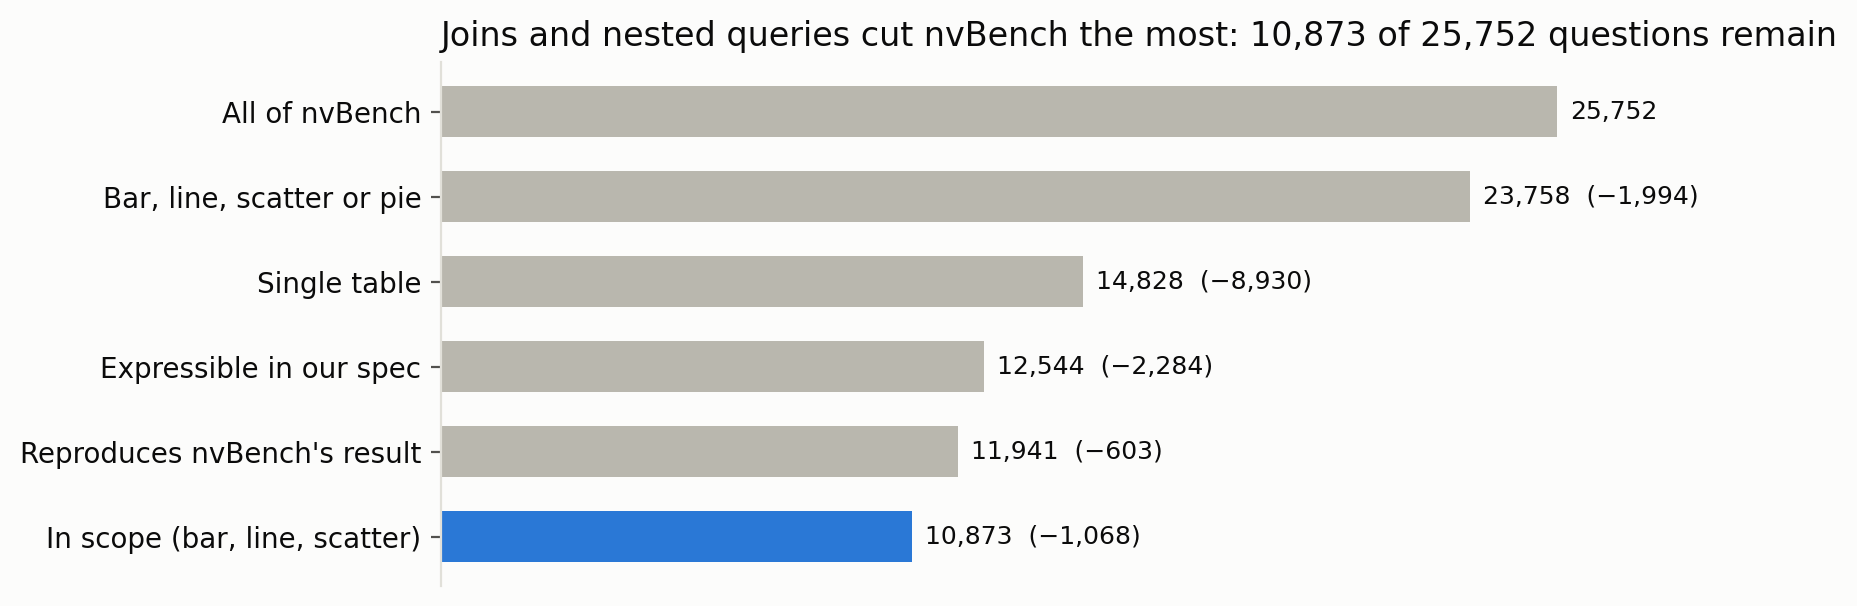

visualisations  \
stage        reason                                                        
single_table join                                                   2382   
             nested query                                            541   
chart_type   Stacked Bar (needs a series column)                     359   
scope        Pie is out of scope                                     268   
operations   OR in WHERE                                             195   
             WHERE operator LIKE                                     165   
chart_type   Grouping Scatter (needs a series column)                129   
validation   binned chart differs from nvBench's vis_obj             104   
             nvBench bins years into ranges                           73   
chart_type   Grouping Line (needs a series column)                    72   
operations   ORDER BY a column that is not on an axis                 63   
             LIMIT clause                                             27   
             aggregate on the x axis                                  26   
             WHERE operator NOT                                       24   
             DISTINCT                                                 20   

                                                          questions  
stage        reason                                                  
single_table join                                              6795  
             nested query                                      2135  
chart_type   Stacked Bar (needs a series column)               1172  
scope        Pie is out of scope                               1068  
operations   OR in WHERE                                        804  
             WHERE operator LIKE                                765  
chart_type   Grouping Scatter (needs a series column)           551  
validation   binned chart differs from nvBench's vis_obj        341  
             nvBench bins years into ranges                     232  
chart_type   Grouping Line (needs a series column)              271  
operations   ORDER BY a column that is not on an axis           248  
             LIMIT clause                                        67  
             aggregate on the x axis                             98  
             WHERE operator NOT                                  55  
             DISTINCT                                            82

Converted specs that reproduce the SQL result: 2717 of 2724
Converted specs that reproduce the vis_obj (binned): 289 of 466
Kept unbinned visualisations that also equal nvBench's vis_obj: 86.6%


In [22]:
CHART_LABELS = ["Bar", "Line", "Scatter", "Pie", "Stacked Bar", "Grouping Line", "Grouping Scatter"]
STAGE_LABELS = ["All of nvBench", "Bar, line, scatter or pie", "Single table", "Expressible in our spec",
                "Reproduces nvBench's result", "In scope (bar, line, scatter)"]


def process(record: VisRecord) -> tuple[Conversion, bool]:
    """Convert and validate one record; return its conversion and whether it matches vis_obj."""
    db_file = database_file(record.db_id)
    conversion = convert(record.chart, record.sql, record.binning, table_columns(db_file))
    try:
        chart = execute_spec(conversion.spec, load_table(db_file, conversion.table))
    except ExecutionError as error:
        raise Unsupported("validation", f"executor error: {error}") from error
    if conversion.spec.bin:  # SQLite cannot bin: nvBench's own chart data is the reference
        if any("~" in str(x) for x in (record.vis_obj["x_data"] or [[]])[0]):
            raise Unsupported("validation", "nvBench bins years into ranges")
        if not matches_vis_obj(chart, record.vis_obj, binned=True):
            raise Unsupported("validation", "binned chart differs from nvBench's vis_obj")
    else:
        try:
            gold = chart_rows(execute_sql(db_file, record.sql))
        except sqlite3.Error as error:
            raise Unsupported("validation", "the nvBench SQL fails in SQLite") from error
        if not same_chart_data(chart_rows(chart), gold, conversion.sql_sort):
            raise Unsupported("validation", "chart data differs from the SQL result")
    if conversion.spec.chart_type not in CONFIG["chart_types"]:
        raise Unsupported("scope", f"{record.chart} is out of scope")
    return conversion, matches_vis_obj(chart, record.vis_obj)


statuses, conversions = [], {}
for record in sorted(records, key=lambda r: (r.db_id, r.key)):  # grouped by database for the table cache
    status = {"key": record.key, "chart": record.chart, "binned": bool(record.binning), "questions": len(record.questions),
              "stage": "kept", "reason": "", "vis_obj_match": None}
    try:
        conversions[record.key], status["vis_obj_match"] = process(record)
    except Unsupported as skip:
        status.update(stage=skip.stage, reason=skip.reason)
    statuses.append(status)
status = pd.DataFrame(statuses)
rank = status["stage"].map({s: i for i, s in enumerate(STAGES)} | {"kept": len(STAGES)})
funnels = {}
for unit, weight in (("visualisations", None), ("questions", "questions")):
    rows = {label: (status[rank >= i].groupby("chart")[weight].sum() if weight else status[rank >= i]["chart"].value_counts())
            .reindex(CHART_LABELS, fill_value=0) for i, label in enumerate(STAGE_LABELS)}
    funnels[unit] = pd.DataFrame(rows).T.assign(Total=lambda t: t.sum(axis=1))
    save_table(funnels[unit], f"data_funnel_{unit}")
    display(funnels[unit])
display(Image(plot_funnel(funnels["questions"]["Total"])))

rejections = status[status["stage"] != "kept"].groupby(["stage", "reason"]).agg(
    visualisations=("key", "size"), questions=("questions", "sum")).sort_values("visualisations", ascending=False)
save_table(rejections, "data_rejections")
display(rejections.head(15))
for binned, label in ((False, "SQL result"), (True, "vis_obj (binned)")):
    tried = status[(status["binned"] == binned) & rank.ge(STAGES.index("validation"))]
    print(f"Converted specs that reproduce the {label}: {tried['stage'].isin(['kept', 'scope']).sum()} of {len(tried)}")
kept = status[(status["stage"] == "kept") & ~status["binned"]]
print(f"Kept unbinned visualisations that also equal nvBench's vis_obj: {kept['vis_obj_match'].astype(bool).mean():.1%}")

## 23. Splits, schemas and processed files

One example per (question, visualisation), exact duplicates removed. The splits go to `data/processed/{train,val,test}.jsonl` and every table's serialised schema to `schemas.json`.

Largest relative category imbalance in val/test: 82%; test databases: ['behavior_monitoring', 'bike_1', 'candidate_poll', 'car_1', 'cre_Doc_Control_Systems', 'cre_Theme_park', 'customers_and_addresses', 'customers_and_invoices', 'dorm_1', 'driving_school', 'loan_1', 'solvency_ii', 'store_1', 'student_transcripts_tracking']


,train,val,test
databases,107,21,14
visualisations,2103,361,272
questions,8540,1217,1116
bar questions,7763,1078,955
line questions,459,60,85
scatter questions,318,79,76


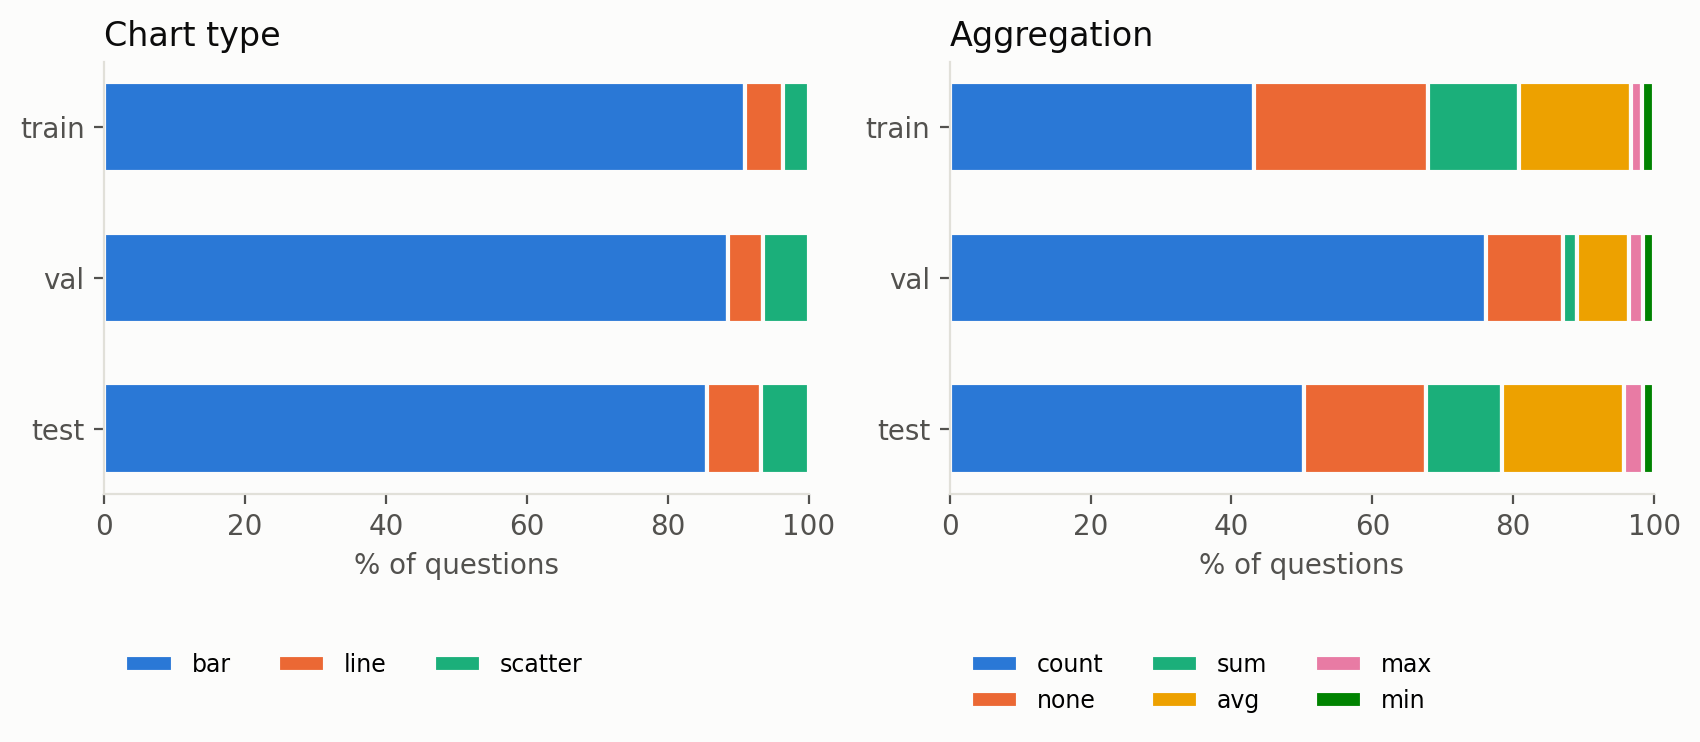

255 tables; schema length in characters: median 270, max 1519 (soccer_1/Player_Attributes)


In [23]:
by_key = {r.key: r for r in records}
examples = []
for key, conversion in sorted(conversions.items()):
    seen = set()
    for i, question in enumerate(by_key[key].questions):
        if question.lower() not in seen:
            seen.add(question.lower())
            examples.append({"id": f"{key}#{i}", "vis_key": key, "db_id": by_key[key].db_id, "table": conversion.table,
                             "question": question, "spec": conversion.spec.to_dict(), "chart_type": conversion.spec.chart_type,
                             "hardness": by_key[key].hardness, "sql": by_key[key].sql})
splits = split_by_database(examples, CONFIG["split_fractions"], CONFIG["seed"], CONFIG["split_candidates"])
for name in SPLITS:
    write_jsonl(PATHS["processed_dir"] / f"{name}.jsonl", splits[name])
owners = {name: {ex["db_id"] for ex in splits[name]} for name in SPLITS}
assert not (owners["train"] & owners["val"] or owners["train"] & owners["test"] or owners["val"] & owners["test"])
schemas = {}
for ex in examples:
    key = f"{ex['db_id']}/{ex['table']}"
    if key not in schemas:
        schemas[key] = serialise_table(ex["table"], load_table(database_file(ex["db_id"]), ex["table"]), **CONFIG["schema"])
(PATHS["processed_dir"] / "schemas.json").write_text(json.dumps(schemas, indent=1, ensure_ascii=False), encoding="utf-8")

split_stats = pd.DataFrame({name: {"databases": len(owners[name]), "visualisations": len({ex["vis_key"] for ex in splits[name]}),
                                   "questions": len(splits[name]),
                                   **{f"{c} questions": sum(ex["chart_type"] == c for ex in splits[name]) for c in CONFIG["chart_types"]}}
                            for name in SPLITS})
save_table(split_stats, "data_splits")
print(f"Largest relative category imbalance in val/test: {imbalance(splits, examples):.0%}; test databases: {sorted(owners['test'])}")
display(split_stats)
display(Image(plot_split_mix(splits)))
lengths = pd.Series({k: len(v) for k, v in schemas.items()})
print(f"{len(schemas)} tables; schema length in characters: median {lengths.median():.0f}, max {lengths.max()} ({lengths.idxmax()})")

## 24. Load the project and build the hand-written test set

30 informal questions about three real datasets that ship with Plotly: `tips`, `gapminder` and `stocks`. Where several chart types are reasonable, the gold lists them all. Every gold spec is checked to run and return data. `LIMIT = 20` gives a quick smoke test; `OVERWRITE = True` discards saved predictions and models.

In [24]:
from transformers import AutoTokenizer

LIMIT, OVERWRITE = None, False
project = load_project(CONFIG)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
tokenizer = AutoTokenizer.from_pretrained(CONFIG["models"]["t5"])  # the T5 target must survive tokenisation unchanged
targets = [spec_to_text(ChartSpec.from_dict(ex["spec"])) for ex in project.splits["train"]]
print("Training targets unchanged by T5 tokenisation:", sum(tokenizer.decode(tokenizer(t).input_ids, skip_special_tokens=True,
      clean_up_tokenization_spaces=False) == t for t in targets), "of", len(targets))

hw_dir = PATHS["handwritten_dir"]
hw_dir.mkdir(parents=True, exist_ok=True)
for name in ("tips", "gapminder", "stocks"):
    if not (hw_dir / f"{name}.csv").exists():
        getattr(px.data, name)().to_csv(hw_dir / f"{name}.csv", index=False)


def gold(chart, x, y, aggregation=None, bin=None, filters=(), sort=None) -> dict:
    return {"chart_type": chart, "x": x, "y": y, "aggregation": aggregation, "group_by": x if aggregation else None, "bin": bin,
            "filters": [{"column": c, "op": o, "value": v} for c, o, v in filters], "sort": sort and {"by": sort[0], "order": sort[1]}}


BL, LB = ["bar", "line"], ["line", "bar"]
HANDWRITTEN = {
    "tips": [
        ("which day do people tip the most on average?", gold("bar", "day", "tip", "avg")),
        ("how many tables did they serve on each day", gold("bar", "day", "*", "count")),
        ("total bill amount for lunch vs dinner", gold("bar", "time", "total_bill", "sum")),
        ("is there any relationship between how big the bill is and the tip?", gold("scatter", "total_bill", "tip")),
        ("biggest tip left by smokers and non smokers", gold("bar", "smoker", "tip", "max")),
        ("avg party size per day, biggest first", gold("bar", "day", "size", "avg", sort=("y", "desc"))),
        ("how many groups had more than 4 people, split by day", gold("bar", "day", "*", "count", filters=[("size", ">", 4)])),
        ("for dinner only, plot the tip against the total bill", gold("scatter", "total_bill", "tip", filters=[("time", "=", "Dinner")])),
        ("cheapest bill on each day of the week", gold("bar", "day", "total_bill", "min")),
        ("count of male vs female payers", gold("bar", "sex", "*", "count")),
        ("for each size of group whats the average tip", gold(BL, "size", "tip", "avg")),
        ("on saturdays how does the tip relate to the bill", gold("scatter", "total_bill", "tip", filters=[("day", "=", "Sat")])),
    ],
    "gapminder": [
        ("how has life expectancy in Australia changed over the years", gold(LB, "year", "lifeExp", filters=[("country", "=", "Australia")])),
        ("average life expectancy per continent in 2007", gold("bar", "continent", "lifeExp", "avg", filters=[("year", "=", 2007)])),
        ("world population over time", gold(LB, "year", "pop", "sum")),
        ("gdp per capita vs life expectancy for 2007", gold("scatter", "gdpPercap", "lifeExp", filters=[("year", "=", 2007)])),
        ("how many countries does each continent have in the 1952 data", gold("bar", "continent", "*", "count", filters=[("year", "=", 1952)])),
        ("which continents had the most people in 2007? highest first", gold("bar", "continent", "pop", "sum", filters=[("year", "=", 2007)], sort=("y", "desc"))),
        ("average gdp per capita by year", gold(LB, "year", "gdpPercap", "avg")),
        ("best life expectancy recorded in each continent", gold("bar", "continent", "lifeExp", "max")),
        ("lowest life expectancy per continent in 1952, low to high", gold("bar", "continent", "lifeExp", "min", filters=[("year", "=", 1952)], sort=("y", "asc"))),
        ("plot China's population through the years", gold(LB, "year", "pop", filters=[("country", "=", "China")])),
        ("total population of Asia over the years", gold(LB, "year", "pop", "sum", filters=[("continent", "=", "Asia")])),
    ],
    "stocks": [
        ("how did apple's stock do over time", gold("line", "date", "AAPL")),
        ("average netflix price per month", gold(BL, "date", "NFLX", "avg", bin="month")),
        ("compare google and amazon prices on a scatter plot", gold("scatter", "GOOG", "AMZN")),
        ("avg microsoft price for each year", gold(BL, "date", "MSFT", "avg", bin="year")),
        ("number of weeks per year where amazon was above 1.5", gold(BL, "date", "*", "count", bin="year", filters=[("AMZN", ">", 1.5)])),
        ("highest google price each year", gold(BL, "date", "GOOG", "max", bin="year")),
        ("show the trend of facebook stock, latest first", gold("line", "date", "FB", sort=("x", "desc"))),
    ],
}
project.splits["handwritten"] = [
    {"id": f"hw_{t}_{i:02d}", "db_id": "handwritten", "table": t, "csv": (hw_dir / f"{t}.csv").relative_to(ROOT).as_posix(),
     "question": q, "spec": s, "chart_type": acceptable_charts(s)[0]}
    for t, questions in HANDWRITTEN.items() for i, (q, s) in enumerate(questions)
]
for ex in project.splits["handwritten"]:
    assert len(execute_spec(gold_spec(ex["spec"]), project.table(ex))) > 0, ex["question"]
write_jsonl(PATHS["processed_dir"] / "handwritten.jsonl", project.splits["handwritten"])
print({name: len(exs) for name, exs in project.splits.items()})

GPU: NVIDIA GeForce RTX 5070 Ti


Training targets unchanged by T5 tokenisation: 8540 of 8540
{'train': 8540, 'val': 1217, 'test': 1116, 'handwritten': 30}


## 25. Baselines (systems 1-3)

The system overview first. The rule-based system and the two few-shot systems need no training. They run on the validation, test and hand-written questions.

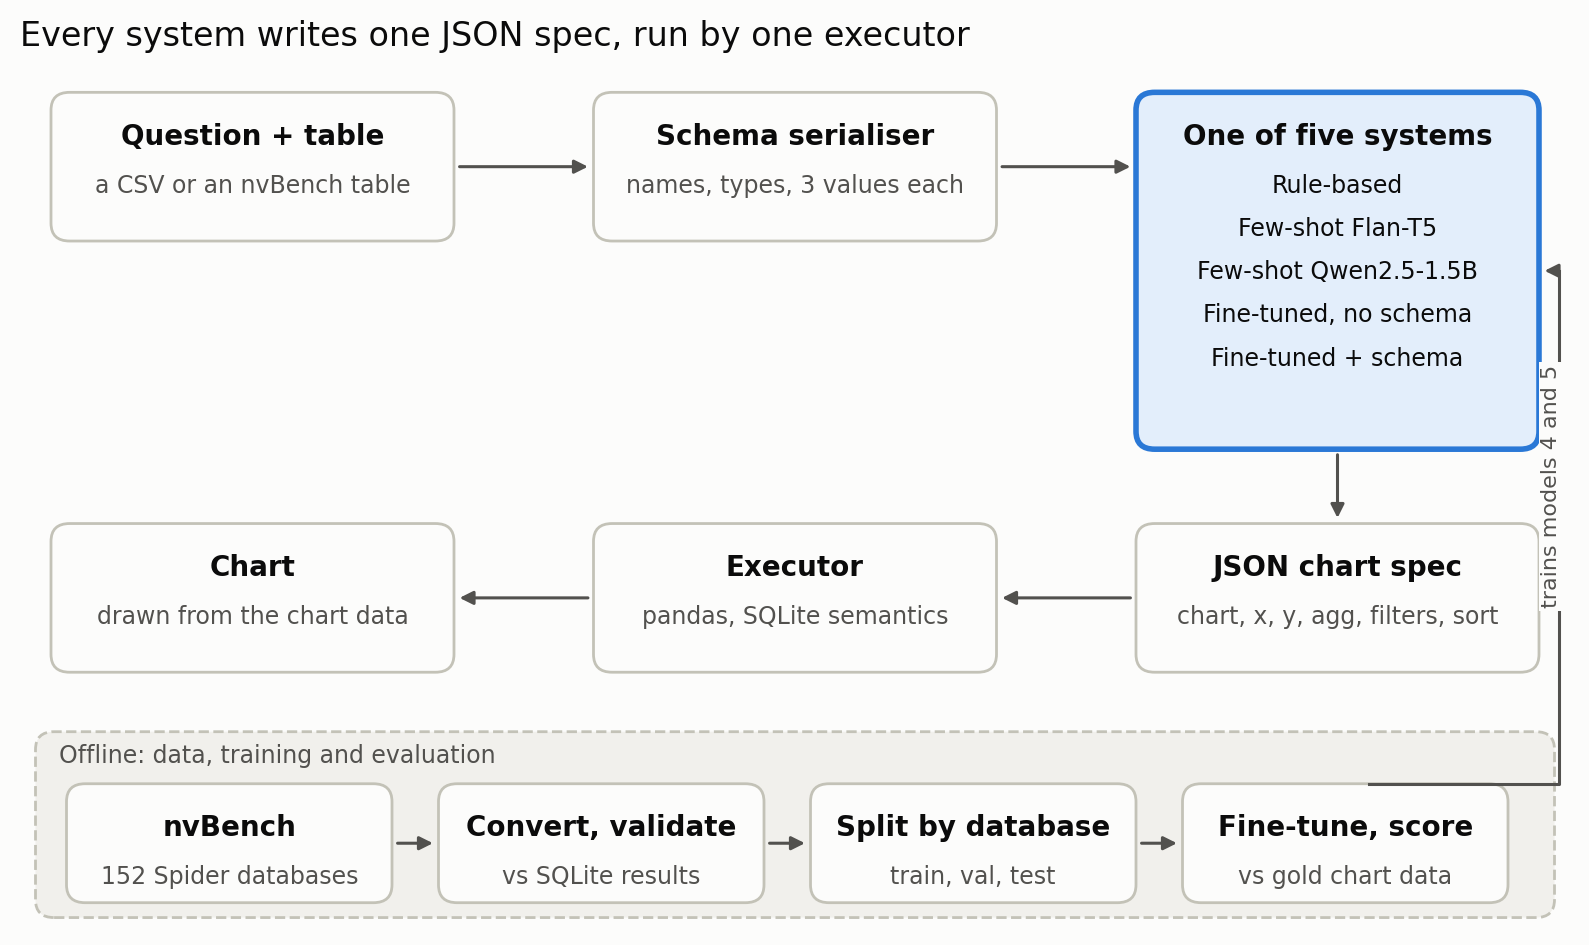

- Show how many country from each country, show bars in desc order.
  chart: bar ; x: Country ; y: * ; agg: count ; bin: none ; filters: none ; sort: x desc
- Return a histogram on how old is the average person for each job?
  chart: bar ; x: job ; y: age ; agg: avg ; bin: none ; filters: none ; sort: none
- List the final tables made and the best finishes of poker players. Show the correlation.
  chart: scatter ; x: Final_Table_Made ; y: Best_Finish ; agg: none ; bin: none ; filters: none ; sort: none
- Return a line chart about the change of the amount of Start_from over  Start_from bin start_from by time.
  chart: line ; x: Start_from ; y: * ; agg: count ; bin: year ; filters: none ; sort: none
rule_based: all predictions already exist
few_shot_t5: all predictions already exist
few_shot_llm: all predictions already exist


In [25]:
EVAL_SPLITS = ["val", "test", "handwritten"]
display(Image(plot_overview()))
for shot in select_shots(project, CONFIG["seed"]):
    print(f"- {shot['question']}\n  {spec_to_text(ChartSpec.from_dict(shot['spec']))}")
for name in ["rule_based", "few_shot_t5", "few_shot_llm"]:
    predict_system(name, project, EVAL_SPLITS, OVERWRITE, LIMIT)

## 26. Fine-tuning (systems 4 and 5)

The two runs differ only in whether the serialised schema is part of the input.

ft_schema: trained model found, skipping training
ft_schema: all predictions already exist
ft_schema {'system': 'ft_schema', 'date': '2026-10-15', 'base_model': 'google/flan-t5-base', 'use_schema': True, 'seed': 42, 'epochs': 8, 'batch_size': 16, 'learning_rate': 0.0003, 'warmup_ratio': 0.05, 'weight_decay': 0.01, 'max_input_tokens': 512, 'max_target_tokens': 128, 'train_examples': 8540, 'val_examples': 1217, 'train_inputs_cut': 0, 'val_inputs_cut': 53, 'best_checkpoint': 'C:\\Users\\Antony John Alappat\\Downloads\\UTS ASSIGNMENTS\\new\\nlp\\nl2vis\\outputs\\ft_schema\\checkpoint-534', 'best_val_loss': 0.04290159419178963, 'minutes': 15.8, 'gpu': 'NVIDIA GeForce RTX 5070 Ti'}
ft_no_schema: trained model found, skipping training
ft_no_schema: all predictions already exist
ft_no_schema {'system': 'ft_no_schema', 'date': '2026-10-15', 'base_model': 'google/flan-t5-base', 'use_schema': False, 'seed': 42, 'epochs': 8, 'batch_size': 16, 'learning_rate': 0.0003, 'warmup_ratio': 0.05, 'weight_

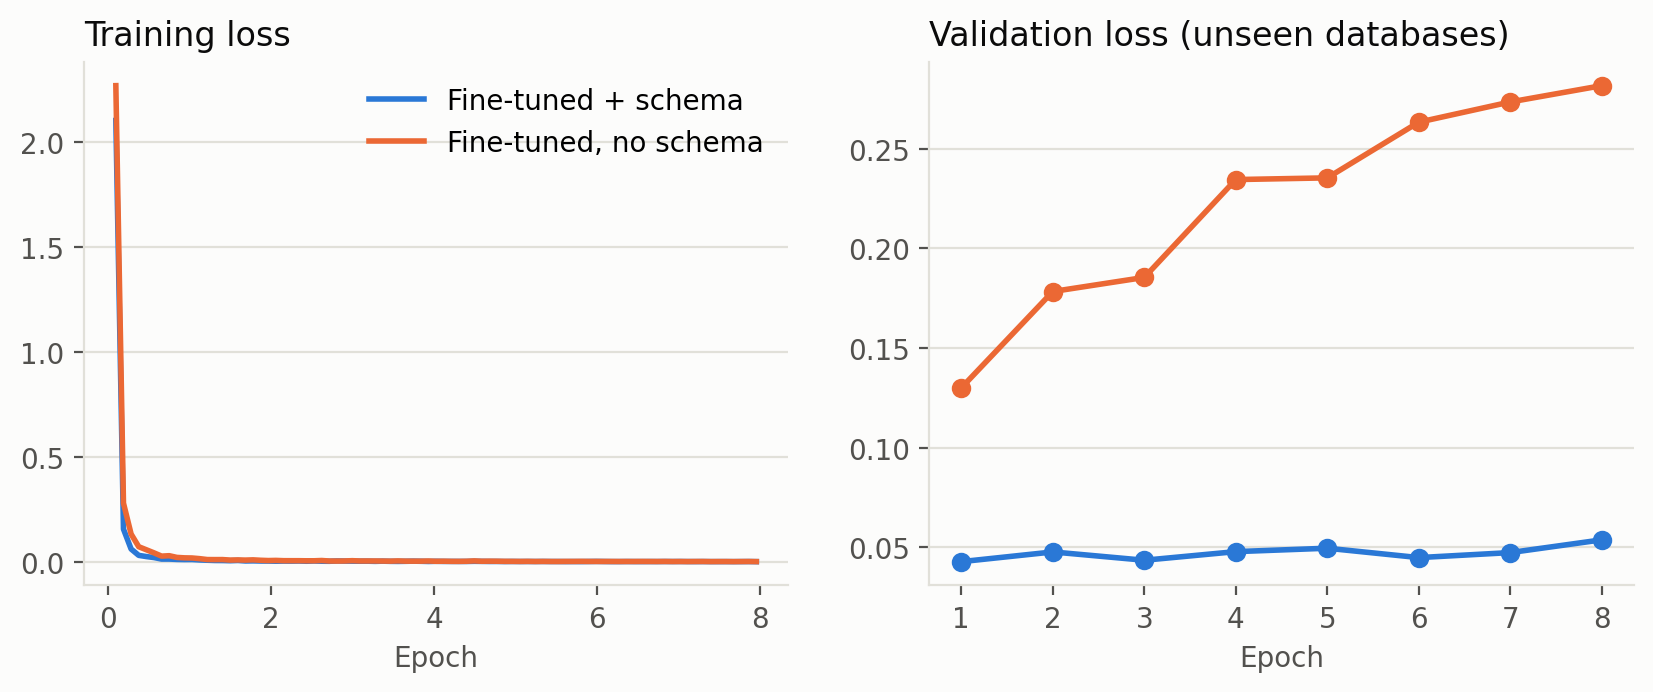

In [26]:
FINE_TUNED = ["ft_schema", "ft_no_schema"]
for name in FINE_TUNED:
    train_t5(name, project, OVERWRITE)
    predict_system(name, project, EVAL_SPLITS, OVERWRITE, LIMIT)
    print(name, json.loads((run_dir(name) / "run_config.json").read_text(encoding="utf-8")))
display(Image(plot_training_curves({name: run_dir(name) / "log_history.json" for name in FINE_TUNED})))

## 27. Results

Scores of all five systems on validation, test (14 unseen databases) and the hand-written questions, the chart-type confusion matrices, and McNemar tests of the schema-aware model against each other system.

,Chart type,x column,y column,Aggregation,Validity,Exact match,Execution match,Bin,Filters,Sort,Raw invalid output,Questions
system,,,,,,,,,,,,
Rule-based,98.4,75.4,78.9,86.2,100.0,39.2,42.7,86.4,83.4,79.1,0.0,1116.0
Few-shot Flan-T5,0.1,0.0,0.1,0.1,0.1,0.0,0.0,0.1,0.1,0.0,99.9,1116.0
Few-shot Qwen2.5-1.5B,79.5,76.8,70.2,74.0,72.0,46.0,49.6,73.2,69.2,69.3,19.3,1116.0
"Fine-tuned, no schema",97.8,62.3,88.2,97.0,55.8,48.7,49.9,91.3,80.2,95.2,0.9,1116.0
Fine-tuned + schema,97.7,93.7,95.1,96.7,97.0,72.3,73.6,91.7,86.0,95.0,1.2,1116.0


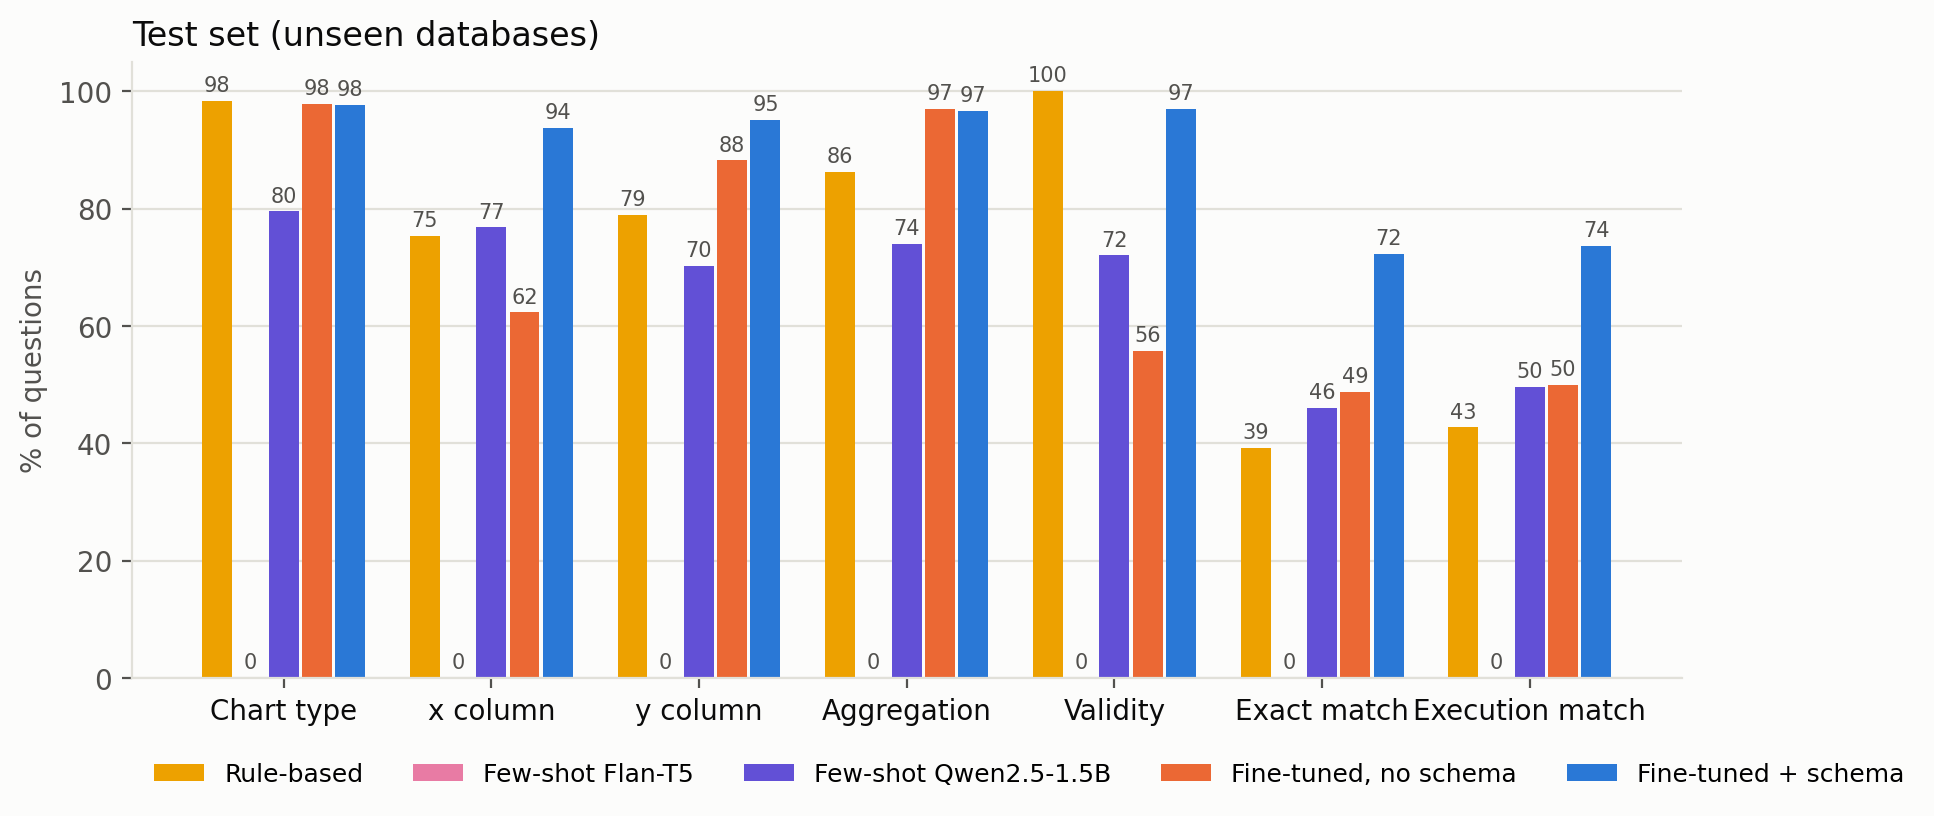

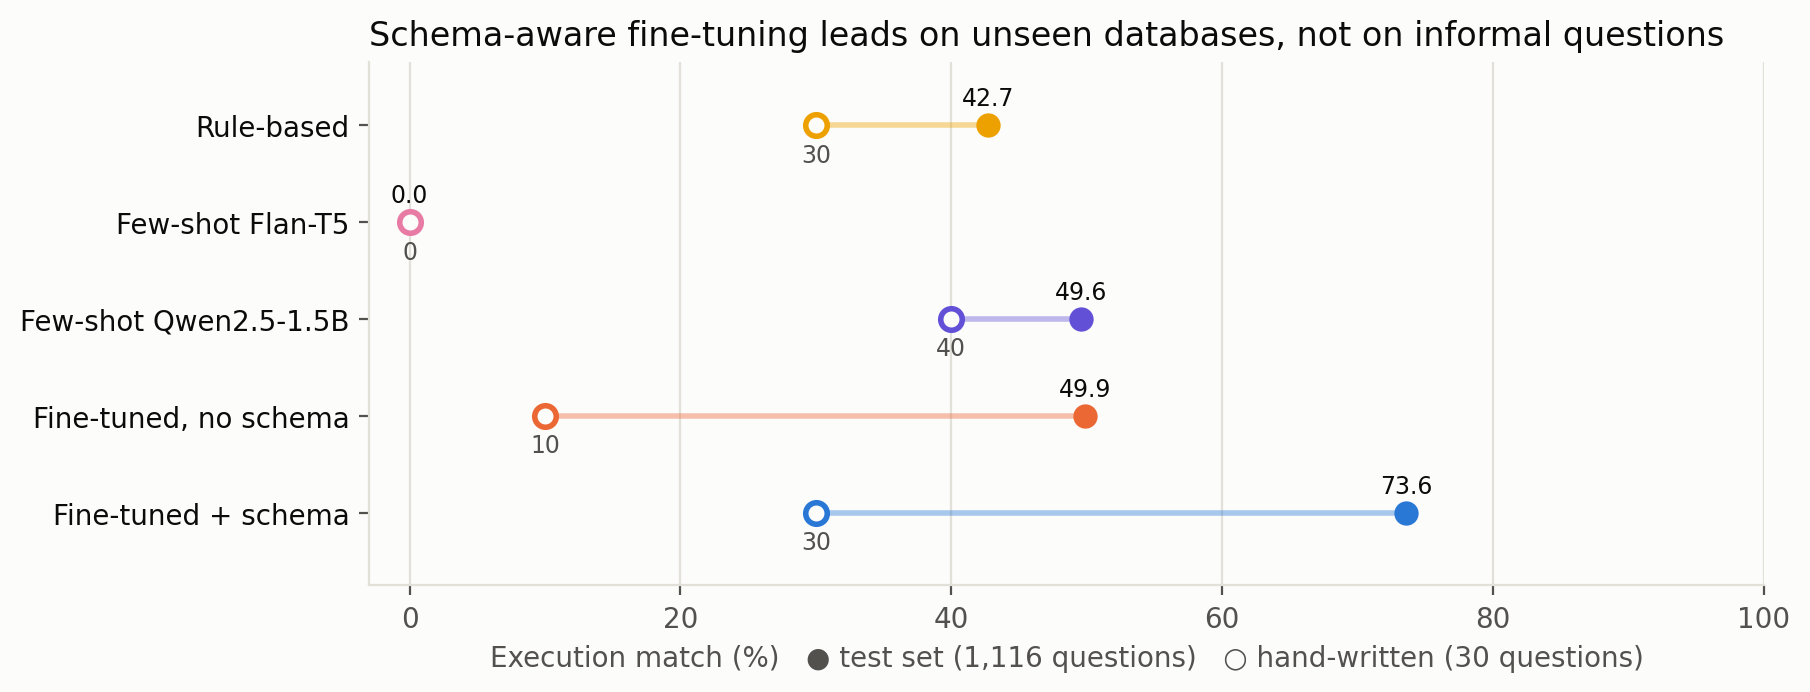

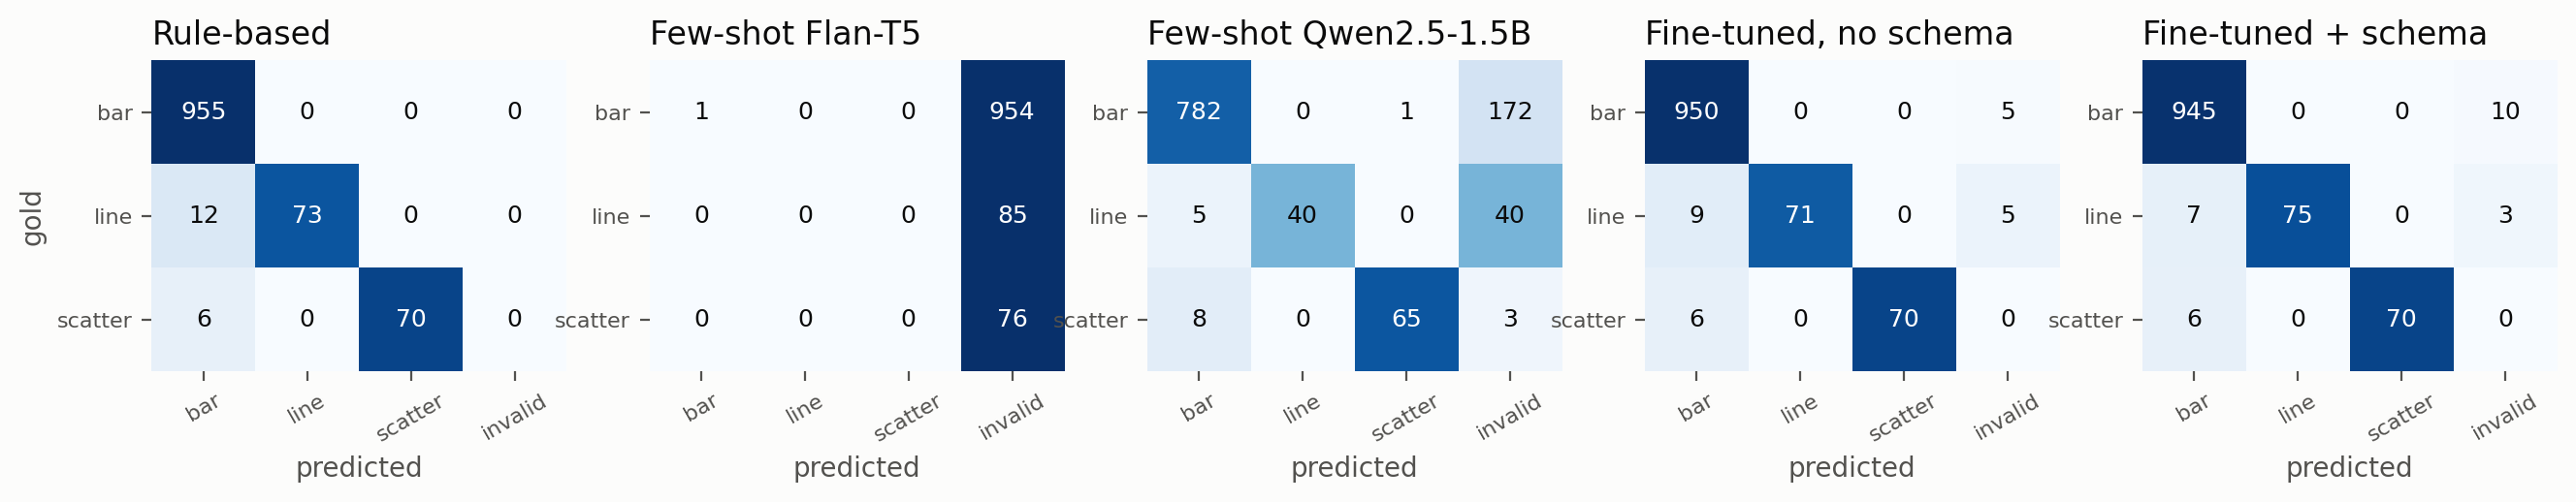

,system_a,only_a_correct,only_b_correct,p_value
system_b,,,,
rule_based,ft_schema,350,6,3.756567e-95
few_shot_t5,ft_schema,821,0,1.430222e-247
few_shot_llm,ft_schema,295,28,2.298946e-57
ft_no_schema,ft_schema,269,5,8.327830e-73


In [27]:
SYSTEMS = list(CONFIG["systems"])
scored = {split: {name: score_system(name, split, project) for name in SYSTEMS} for split in EVAL_SPLITS}
summaries = {}
for split in EVAL_SPLITS:
    summaries[split] = summarise(scored[split])
    save_table(summaries[split].rename(index=SYSTEM_LABELS), f"summary_{split}")
    pd.concat(scored[split].values()).to_json(PATHS["results_dir"] / f"scored_{split}.jsonl", orient="records", lines=True, force_ascii=False)
display(summaries["test"].rename(index=SYSTEM_LABELS))
display(Image(plot_grouped(summaries["test"][[LABELS[m] for m in METRICS]], "Test set (unseen databases)", "metrics_test.png", labels=True)))
display(Image(plot_dumbbell(summaries["test"]["Execution match"], summaries["handwritten"]["Execution match"])))
display(Image(plot_confusions({name: pd.crosstab(f["gold_chart"], f["pred_chart"]).reindex(
    index=CONFIG["chart_types"], columns=CONFIG["chart_types"] + ["invalid"], fill_value=0) for name, f in scored["test"].items()})))
tests = pd.DataFrame([mcnemar(scored["test"]["ft_schema"], scored["test"][other]) for other in SYSTEMS if other != "ft_schema"]).set_index("system_b")
save_table(tests, "significance_test")
tests

## 28. Where the systems succeed and fail

Execution match on the test set broken down by nvBench's hardness level, by the gold chart type, by the width of the table, and by whether the question names the x column verbatim (as nvBench's templates often do). Few-shot Flan-T5 is left out (0% everywhere).

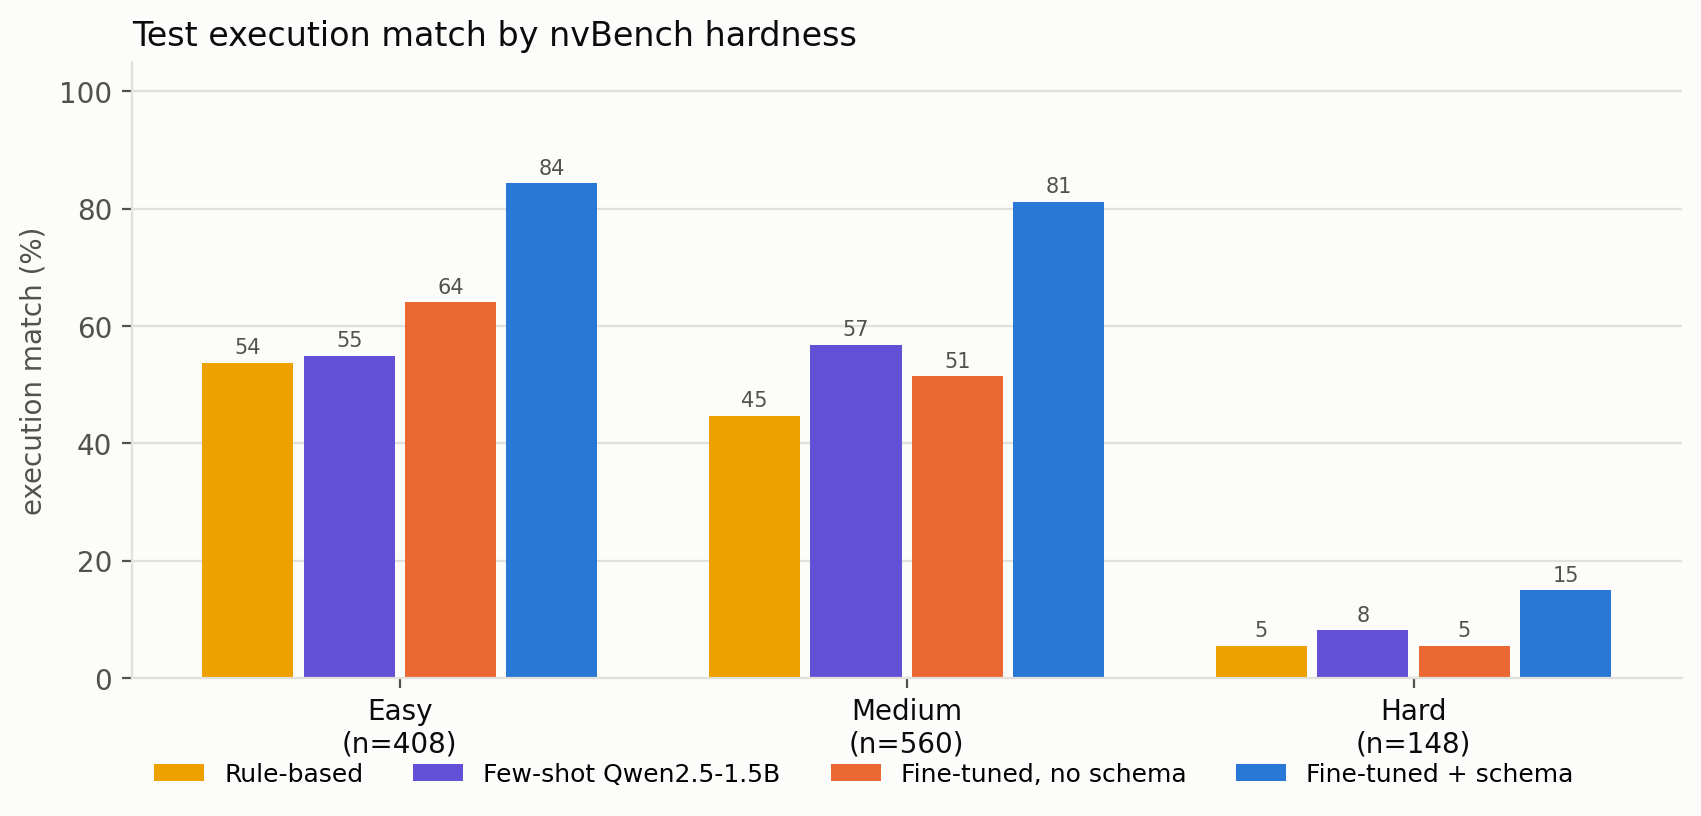

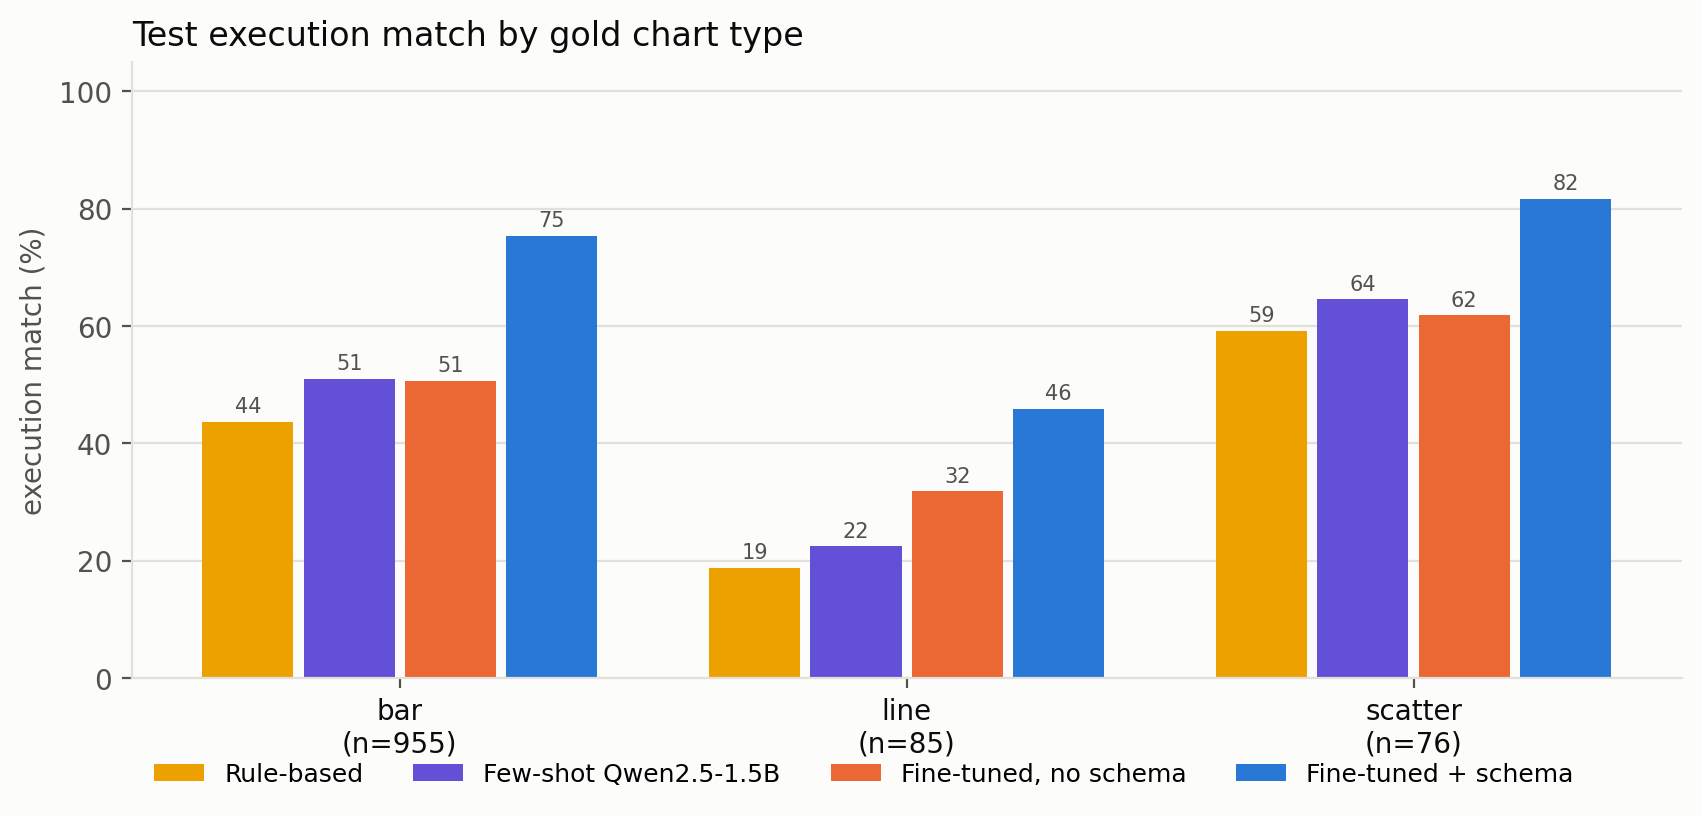

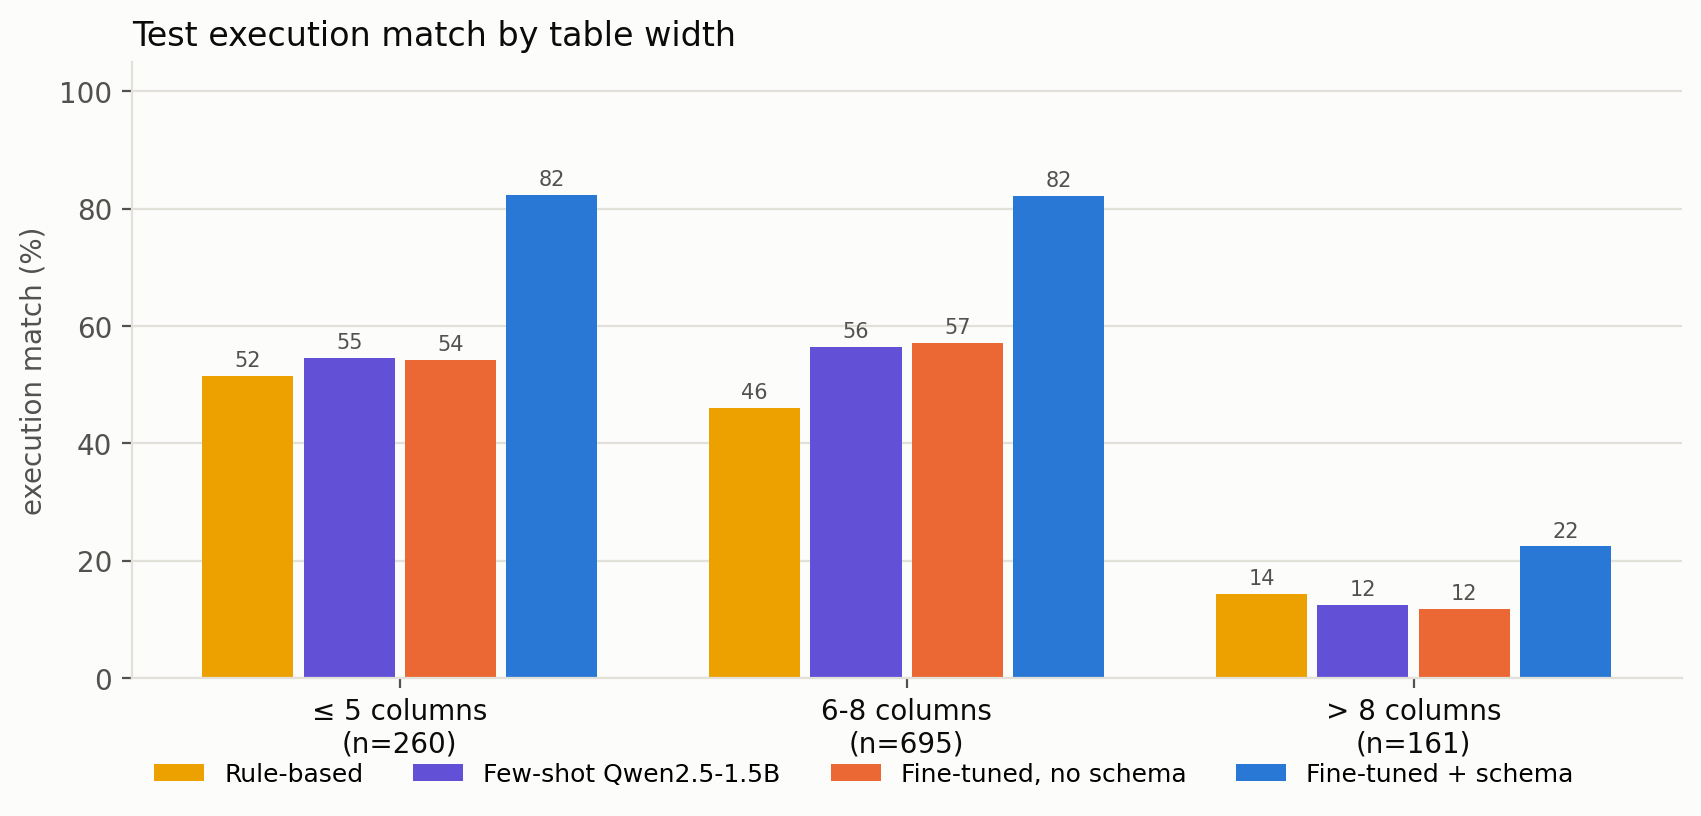

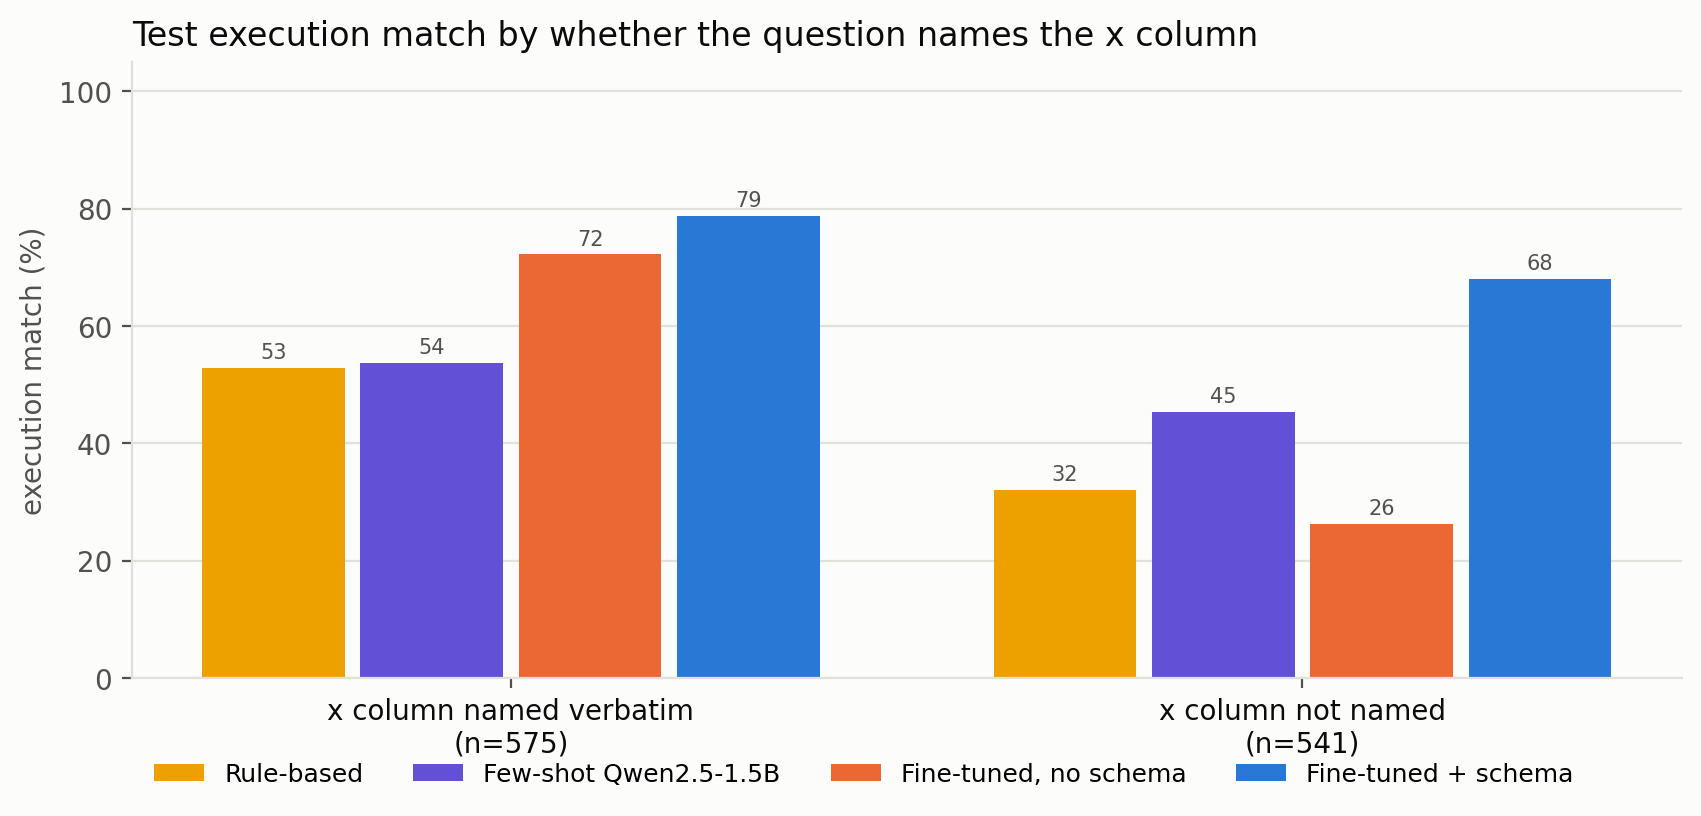

In [28]:
MAIN = {name: f for name, f in scored["test"].items() if name != "few_shot_t5"}
test_frame = pd.concat(MAIN.values())
test_frame["width"] = pd.cut(test_frame["n_columns"], [0, 5, 8, 100], labels=["≤ 5 columns", "6-8 columns", "> 8 columns"])
test_frame["named"] = test_frame["x_named"].map({True: "x column named verbatim", False: "x column not named"})
views = [("hardness", ["Easy", "Medium", "Hard", "Extra Hard"], "by nvBench hardness", "by_hardness.png"),
         ("gold_chart", CONFIG["chart_types"], "by gold chart type", "by_chart_type.png"),
         ("width", ["≤ 5 columns", "6-8 columns", "> 8 columns"], "by table width", "by_table_width.png"),
         ("named", ["x column named verbatim", "x column not named"], "by whether the question names the x column", "by_column_named.png")]
for column, order, title, file in views:
    order = [value for value in order if (test_frame[column] == value).any()]  # no Extra Hard question is single-table
    table = test_frame.groupby(["system", column], observed=True)["execution_match"].mean().mul(100).round(1).unstack().reindex(index=list(MAIN), columns=order)
    table.columns = [f"{c}\n(n={int((test_frame[column] == c).sum() / len(MAIN))})" for c in order]
    save_table(table.rename(index=SYSTEM_LABELS), file.removesuffix(".png"))
    display(Image(plot_grouped(table, f"Test execution match {title}", file, "execution match (%)", labels=True)))

## 29. Error analysis

Failures on the test set by category, with up to six concrete examples per system and category in `results/error_examples.md`.

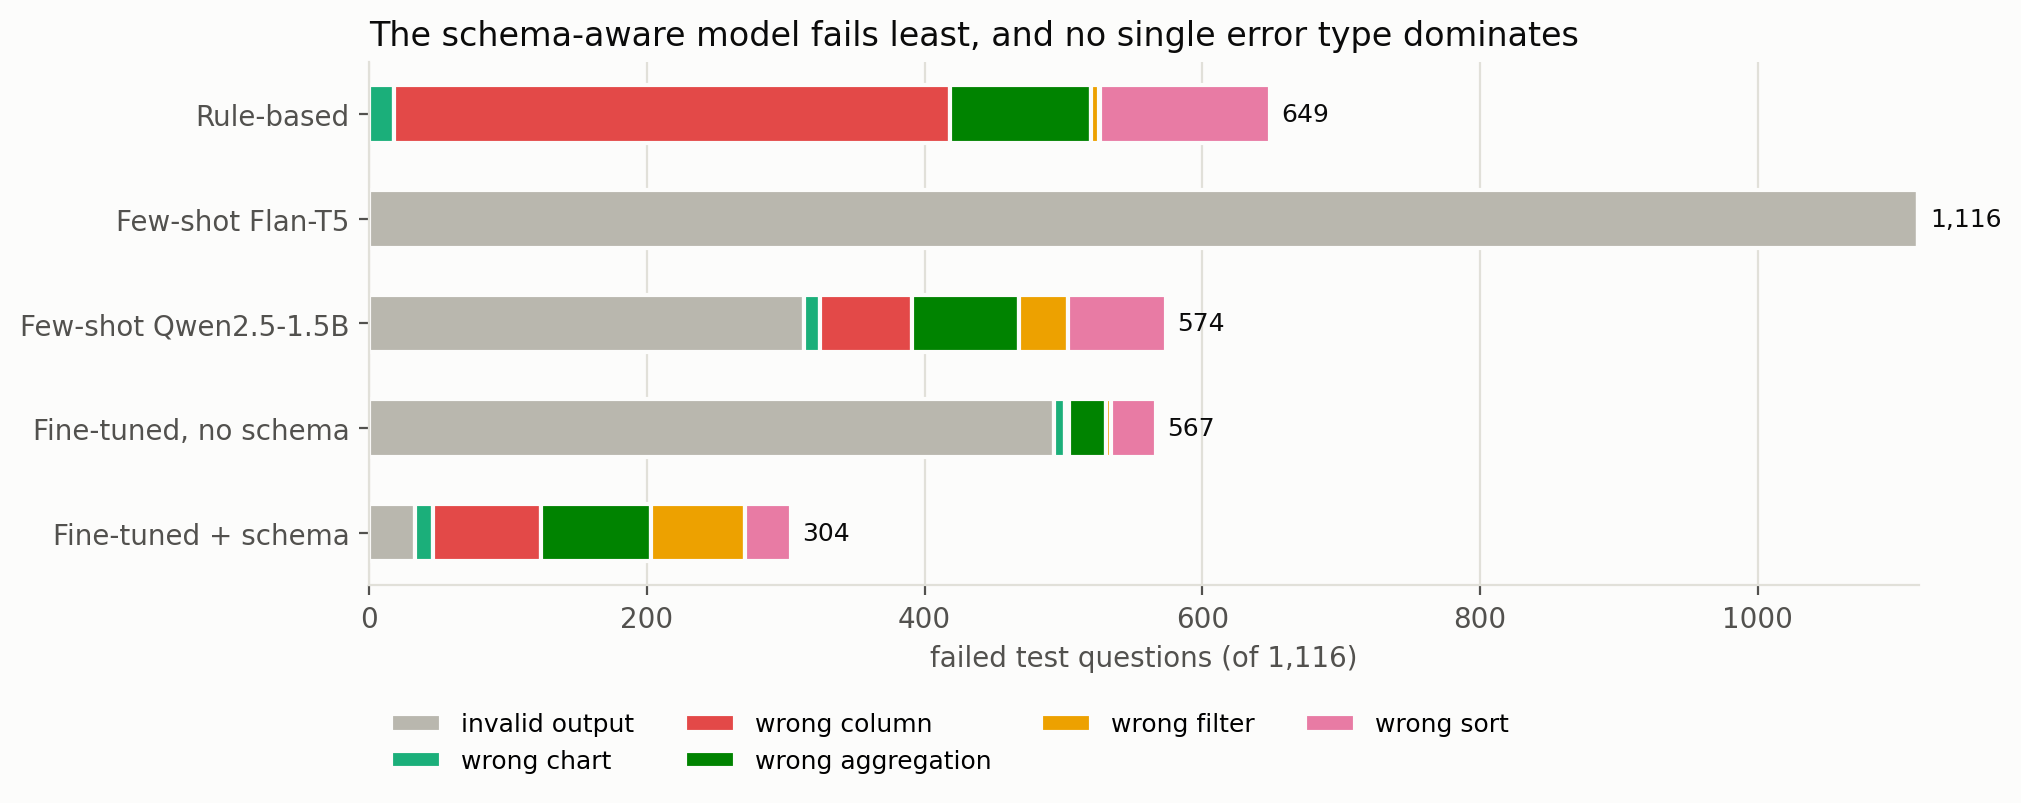

,Chart type,x column,y column,Aggregation,Validity,Exact match,Execution match,Raw invalid output,Hand-written execution match
system,,,,,,,,,
Rule-based,98.4,75.4,78.9,86.2,100.0,39.2,42.7,0.0,30.0
Few-shot Flan-T5,0.1,0.0,0.1,0.1,0.1,0.0,0.0,99.9,0.0
Few-shot Qwen2.5-1.5B,79.5,76.8,70.2,74.0,72.0,46.0,49.6,19.3,40.0
"Fine-tuned, no schema",97.8,62.3,88.2,97.0,55.8,48.7,49.9,0.9,10.0
Fine-tuned + schema,97.7,93.7,95.1,96.7,97.0,72.3,73.6,1.2,30.0


In [29]:
counts = pd.DataFrame({n: f["error_category"].value_counts().reindex(ERROR_CATEGORIES, fill_value=0) for n, f in scored["test"].items()}).T
counts = counts.loc[:, counts.sum() > 0]
save_table(counts.rename(index=SYSTEM_LABELS), "error_counts_test")
display(Image(plot_error_categories(counts)))
examples_md = error_examples_markdown(scored["test"] | {f"{n} (hand-written)": scored["handwritten"][n] for n in SYSTEMS})
(PATHS["results_dir"] / "error_examples.md").write_text(examples_md, encoding="utf-8")
headline = summaries["test"][[LABELS[m] for m in METRICS] + ["Raw invalid output"]].assign(
    **{"Hand-written execution match": summaries["handwritten"]["Execution match"]})
save_table(headline.rename(index=SYSTEM_LABELS), "results_table")
headline.rename(index=SYSTEM_LABELS)

## 30. Demo of the best model

The fine-tuned + schema model answers questions about real CSV files: the JSON spec, a plain-English reading and an interactive Plotly chart for each, plus one static figure for the report. Change `DEMO` to try other questions or tables.

Question: average tip for each day
Spec    : {"chart_type": "bar", "x": "day", "y": "tip", "aggregation": "avg", "group_by": "day", "bin": null, "filters": [], "sort": null} 
Reading : A bar chart of average tip for each day.


Question: Show the number of smokers and non-smokers in a bar chart
Spec    : {"chart_type": "bar", "x": "smoker", "y": "*", "aggregation": "count", "group_by": "smoker", "bin": null, "filters": [], "sort": null} 
Reading : A bar chart of number of rows for each smoker.


Question: Give me the trend of the average life expectancy over the years
Spec    : {"chart_type": "line", "x": "year", "y": "lifeExp", "aggregation": "avg", "group_by": "year", "bin": null, "filters": [], "sort": null} 
Reading : A line chart of average lifeExp for each year.


Question: Visualize the relationship between gdpPercap and lifeExp in a scatter chart
Spec    : {"chart_type": "scatter", "x": "gdpPercap", "y": "lifeExp", "aggregation": null, "group_by": null, "bin": null, "filters": [], "sort": null} 
Reading : A scatter chart of lifeExp against gdpPercap.


Question: Show the trend of AAPL over date
Spec    : {"chart_type": "line", "x": "date", "y": "AAPL", "aggregation": null, "group_by": null, "bin": null, "filters": [], "sort": null} 
Reading : A line chart of AAPL against date.


Question: What is the maximum lifeExp for each continent? Order by the y axis in descending order
Spec    : {"chart_type": "bar", "x": "continent", "y": "lifeExp", "aggregation": "max", "group_by": "continent", "bin": null, "filters": [], "sort": {"by": "y", "order": "desc"}} 
Reading : A bar chart of maximum lifeExp for each continent, sorted by maximum lifeExp (descending).


C:\Users\Antony John Alappat\AppData\Local\Temp\ipykernel_8892\2810889661.py:89: UserWarning:

AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.

C:\Users\Antony John Alappat\AppData\Local\Temp\ipykernel_8892\202724947.py:22: UserWarning:

AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.



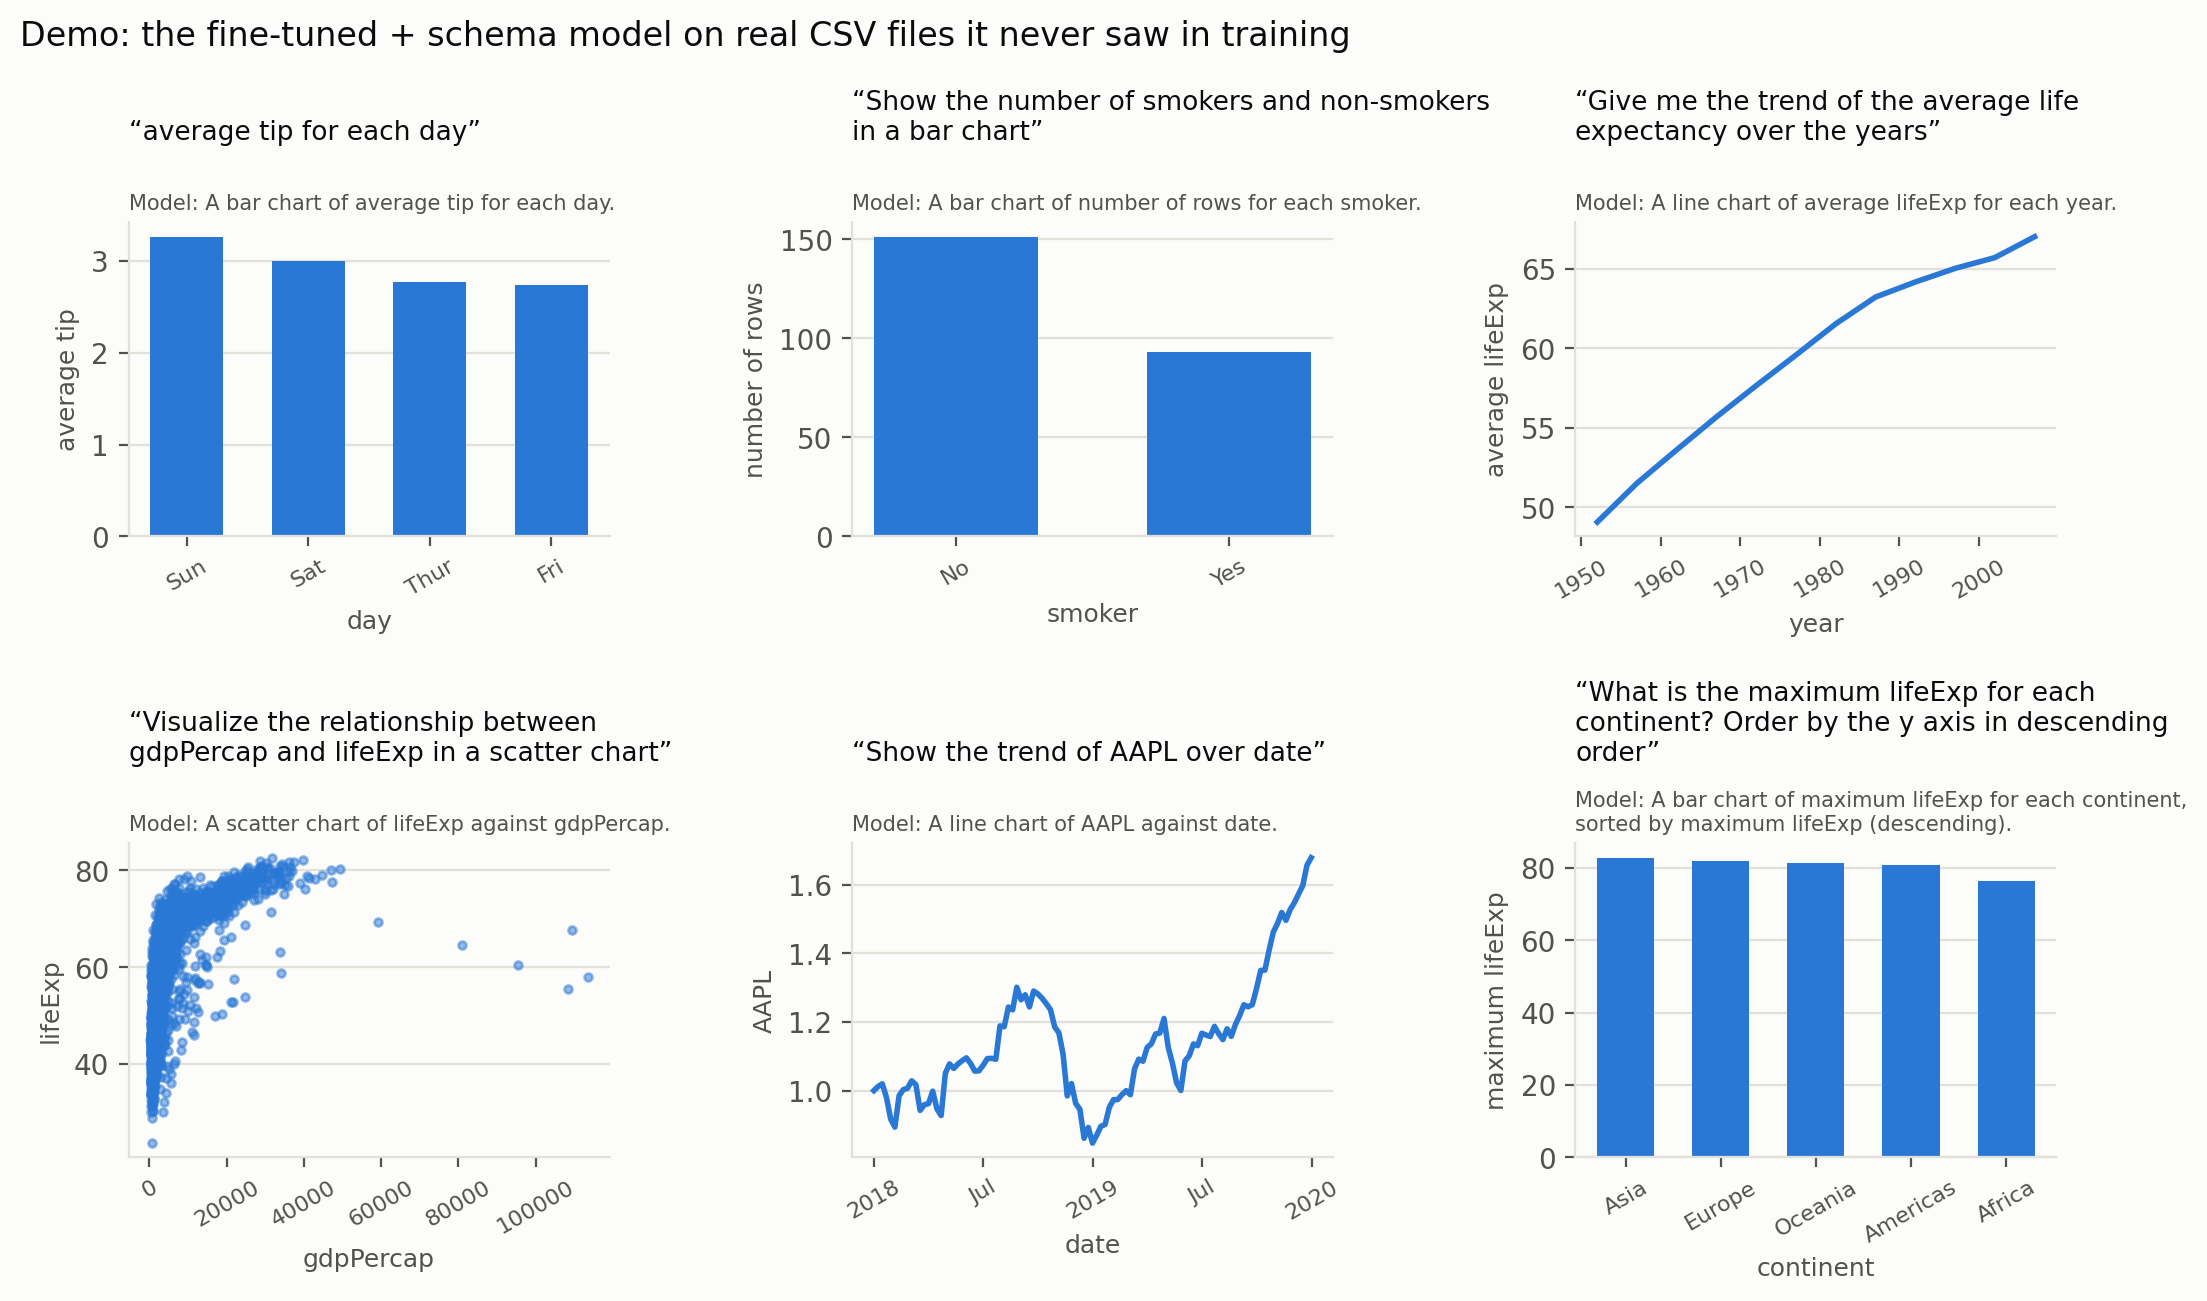

In [30]:
DEMO_SYSTEM = "ft_schema"
DEMO = [("tips", "average tip for each day"),
        ("tips", "Show the number of smokers and non-smokers in a bar chart"),
        ("gapminder", "Give me the trend of the average life expectancy over the years"),
        ("gapminder", "Visualize the relationship between gdpPercap and lifeExp in a scatter chart"),
        ("stocks", "Show the trend of AAPL over date"),
        ("gapminder", "What is the maximum lifeExp for each continent? Order by the y axis in descending order")]
# Informal questions the model gets wrong are analysed in sections 27-29 (e.g. "how many parties came for lunch and dinner").
predict = build_system(DEMO_SYSTEM, project)
demo_results = []
for table_name, question in DEMO:
    table = pd.read_csv(PATHS["handwritten_dir"] / f"{table_name}.csv")
    figure, result = visualise(question, table, predict, table_name)
    if figure is not None:
        figure.show()
    demo_results.append(result)
    print()
display(Image(plot_demo(demo_results)))

## Limitations

- **Data.** nvBench questions are partly templated and often name columns verbatim; the 30 hand-written questions probe this but are few. Only single-table bar, line and scatter charts are covered. Binned gold data relies on nvBench's `vis_obj`.
- **Models.** Small models only (Flan-T5-base, a 1.5B prompted LLM), one run per system with a fixed seed. Flan-T5's 512-token limit can cut the last columns of wide tables.
- **Metrics.** Exact match is stricter than the chart needs; execution match can accept a spec that is right for the wrong reason.

nvBench: Luo et al., SIGMOD 2021 (MIT licence), built on Spider (Yu et al., EMNLP 2018). Models: Flan-T5 (Google) and Qwen2.5 (Alibaba Cloud) via Hugging Face. Hand-written tables: datasets bundled with Plotly.